# Analisi bayesiana — B± → K± K+ K−

Branch `bayes`, responsabile: Giacomo. Riusa la stessa preselezione (data hint nel notebook ufficiale) e la stessa parametrizzazione del modello di massa concordate con Marco (branch `freq`), vedi `Docs/Proposta_progetto_LHCb_gruppo.tex`, sezione "Estensione bayesiana". Il modello vero e proprio (pdf, prior, likelihood) è in `bayesian_model.py`, non ripetuto qui.

**Nota (2026-10-06):** l'interpretazione finale dei risultati e le figure del report sono in `Report/main.tex` (branch `main`), generate da `Report/figures/regen_figures.py`. Rispetto alla versione precedente di questo notebook sono state aggiunte: approssimazione gaussiana del Bayes factor, fit con fondo libero per carica, catene da punti di partenza dispersi, veto sulle risonanze di charm, bias/dispersione dei toy, e significatività Dalitz rispetto all'asimmetria globale (non rispetto a zero). **Attenzione:** le celle nuove non sono ancora state eseguite e gli output visibili (e `results/posterior_summary.json`) sono quelli della run precedente; i valori delle celle nuove sono riportati nel report. Va rieseguito per intero (~5.5 h) per aggiornare gli output.

In [1]:
import sys
import os
import json as _json
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.stats import gaussian_kde

sys.path.insert(0, ".")
import bayesian_model as bm

np.random.seed(42)

# results dir up front (absolute path) + incremental checkpoint helper -- a late-cell failure
# after a long run must not wipe out everything computed before it (lesson learned 2026-09-22)
RESULTS_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

def checkpoint_save(name, data):
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        _json.dump(data, f, indent=2, default=str)
    print(f"[checkpoint] saved {path}")

print("RESULTS_DIR =", RESULTS_DIR)

RESULTS_DIR = /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results


## Lettura dati e preselezione

Preselezione condivisa (presa dal notebook ufficiale, `Code_general/Frequentist/Frequentist_Analysis.ipynb`, non reinventata):
`H*_ProbPi < 0.5 & H*_ProbK > 0.5 & !H*_isMuon` sui tre adroni finali.

In [2]:
DATA_DIR = "../../opendata-project/Data"
FILES = [f"{DATA_DIR}/B2HHH_MagnetDown.root", f"{DATA_DIR}/B2HHH_MagnetUp.root"]

BRANCHES = [f"H{i}_{v}" for i in (1, 2, 3)
            for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for path in FILES:
    with uproot.open(path) as f:
        tree = f["DecayTree"]
        arrs = tree.arrays(BRANCHES, library="pd")
    arrs["magnet"] = "down" if "Down" in path else "up"
    frames.append(arrs)

data = pd.concat(frames, ignore_index=True)
print("total events read:", len(data))

total events read: 8556118


In [3]:
presel = (
    (data.H1_ProbPi < 0.5) & (data.H2_ProbPi < 0.5) & (data.H3_ProbPi < 0.5) &
    (data.H1_ProbK > 0.5) & (data.H2_ProbK > 0.5) & (data.H3_ProbK > 0.5) &
    (~data.H1_isMuon.astype(bool)) & (~data.H2_isMuon.astype(bool)) & (~data.H3_isMuon.astype(bool))
)
data = data[presel].reset_index(drop=True)
print(f"after preselection: {len(data)} ({100*presel.mean():.2f}% of read events)")

after preselection: 23895 (0.28% of read events)


## Ricostruzione della massa invariante (ipotesi KKK) e finestra di fit

Le energie sono calcolate sotto ipotesi di massa di kaone ($M_K = 493.677$ MeV), la massa del B è ricostruita sommando i quadrimpulsi. La finestra di fit (`MASS_LO`, `MASS_HI` in `bayesian_model.py`) è stata scelta dopo aver guardato la distribuzione reale: sotto ~5150 MeV c'è un rialzo di fondo (probabile contributo da decadimenti parzialmente ricostruiti) che un singolo esponenziale non descrive bene — lo escludiamo in questa prima versione invece di complicare il modello di fondo.

In [4]:
M_K = 493.677  # MeV/c^2

def track_energy(px, py, pz, mass):
    return np.sqrt(px**2 + py**2 + pz**2 + mass**2)

for i in (1, 2, 3):
    data[f"H{i}_E"] = track_energy(data[f"H{i}_PX"], data[f"H{i}_PY"], data[f"H{i}_PZ"], M_K)

B_PX = data.H1_PX + data.H2_PX + data.H3_PX
B_PY = data.H1_PY + data.H2_PY + data.H3_PY
B_PZ = data.H1_PZ + data.H2_PZ + data.H3_PZ
B_E = data.H1_E + data.H2_E + data.H3_E

data["B_M"] = np.sqrt(np.clip(B_E**2 - (B_PX**2 + B_PY**2 + B_PZ**2), 0, None))
data["B_Charge"] = data.H1_Charge + data.H2_Charge + data.H3_Charge

data = data[data.B_Charge.isin([1, -1])].reset_index(drop=True)
mask = (data.B_M > bm.MASS_LO) & (data.B_M < bm.MASS_HI)
data = data[mask].reset_index(drop=True)

m_obs = data.B_M.to_numpy()
q_obs = data.B_Charge.to_numpy()
magnet_obs = data.magnet.to_numpy()
print(f"events in fit window [{bm.MASS_LO}, {bm.MASS_HI}] MeV: {len(m_obs)}")
print(f"  B+ : {np.sum(q_obs > 0)}   B- : {np.sum(q_obs < 0)}")
print(f"  magnet down: {np.sum(magnet_obs == 'down')}   magnet up: {np.sum(magnet_obs == 'up')}")

events in fit window [5150.0, 5450.0] MeV: 17839
  B+ : 9358   B- : 8481
  magnet down: 10500   magnet up: 7339


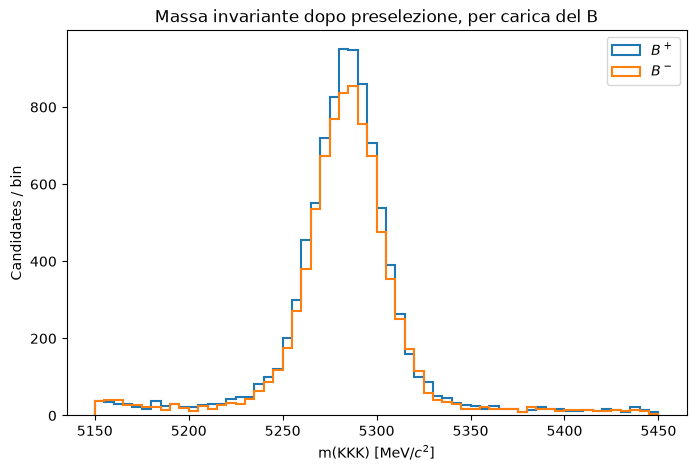

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(bm.MASS_LO, bm.MASS_HI, 61)
ax.hist(m_obs[q_obs > 0], bins=bins, histtype="step", label=r"$B^+$", linewidth=1.5)
ax.hist(m_obs[q_obs < 0], bins=bins, histtype="step", label=r"$B^-$", linewidth=1.5)
ax.set_xlabel("m(KKK) [MeV/$c^2$]")
ax.set_ylabel("Candidates / bin")
ax.legend()
ax.set_title("Massa invariante dopo preselezione, per carica del B")
plt.show()

## Modello di massa e likelihood

$f(m) = N_s\,S(m;\mu,\sigma) + N_b\,B(m;\lambda)$, fit simultaneo con $N_s^+ = N_s(1-A)/2$, $N_s^- = N_s(1+A)/2$ (fondo diviso equamente tra le cariche, nessuna asimmetria di fondo modellata). Segnale = gaussiana troncata, fondo = esponenziale troncato, entrambi normalizzati su $[\mathrm{MASS\_LO}, \mathrm{MASS\_HI}]$. Implementazione in `bayesian_model.py` (`signal_pdf`, `background_pdf`, `log_likelihood`).

## Prior

Prior uniformi a bordi netti (idioma confermato nelle esercitazioni del corso: `0.0` dentro i bordi, `-np.inf` fuori — non HalfNormal). I bordi e il guess iniziale sono stati derivati da un primo sguardo ai dati reali (picco a ~5283 MeV, $N_s\approx 14300$, $N_b\approx 3550$ da una stima sideband vs finestra segnale), vedi `bayesian_model.PRIOR_BOUNDS` / `INITIAL_GUESS`.

In [6]:
for name in bm.PARAM_NAMES:
    lo, hi = bm.PRIOR_BOUNDS[name]
    print(f"{name:12s} bounds=({lo:.4g}, {hi:.4g})  guess={bm.INITIAL_GUESS[name]:.4g}")

theta0 = np.array([bm.INITIAL_GUESS[n] for n in bm.PARAM_NAMES])
lp0 = bm.log_posterior(theta0, m_obs, q_obs)
print("\nlog_posterior at initial guess:", lp0)
assert np.isfinite(lp0), 'initial guess falls outside the prior or gives zero likelihood'

N_s          bounds=(0, 8.92e+04)  guess=1.43e+04
N_b          bounds=(0, 8.92e+04)  guess=3550
A            bounds=(-1, 1)  guess=0
mu           bounds=(5260, 5310)  guess=5283
sigma        bounds=(3, 40)  guess=15
lambda_bkg   bounds=(1e-05, 0.05)  guess=0.0028

log_posterior at initial guess: 59666.50939435986


## Campionamento MCMC (emcee)

Walker inizializzati in una palla stretta attorno al guess iniziale (uno dei due schemi usati nelle esercitazioni del corso, l'altro essendo campionare uniformemente in tutto il box del prior — qui preferiamo la palla stretta per convergere più velocemente su un problema a 6 parametri).

In [7]:
ndim = len(theta0)
nwalkers = 32
nsteps = 9000

spread = np.array([
    0.03 * theta0[0],  # N_s
    0.05 * theta0[1],  # N_b
    0.05,               # A
    1.0,                 # mu
    1.0,                 # sigma
    0.15 * theta0[5],   # lambda_bkg
])
pos = theta0 + spread * np.random.default_rng(42).standard_normal((nwalkers, ndim))
pos[:, 2] = np.clip(pos[:, 2], -0.5, 0.5)  # keep A inside a sane starting range

sampler = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_obs, q_obs))
sampler.run_mcmc(pos, nsteps, progress=True)
print("mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 2/9000 [00:00<07:36, 19.72it/s]

  0%|          | 5/9000 [00:00<06:21, 23.55it/s]

  0%|          | 8/9000 [00:00<07:00, 21.39it/s]

  0%|          | 11/9000 [00:00<07:01, 21.34it/s]

...

100%|█████████▉| 8982/9000 [03:27<00:00, 63.94it/s]

100%|█████████▉| 8989/9000 [03:27<00:00, 60.65it/s]

100%|█████████▉| 8996/9000 [03:27<00:00, 62.23it/s]

100%|██████████| 9000/9000 [03:27<00:00, 43.34it/s]

mean acceptance fraction: 0.5170868055555555


## Diagnostica di convergenza

**Non insegnata nel corso** (verificato: nessun notebook Week4 calcola autocorrelation time o mostra trace plot) — è un'estensione metodologica nostra, non ridondante con quanto fatto a lezione.

autocorrelation time per parametro:
  N_s          tau=76.7  (n_eff ~= 3755)
  N_b          tau=79.2  (n_eff ~= 3636)
  A            tau=71.2  (n_eff ~= 4046)
  mu           tau=60.8  (n_eff ~= 4740)
  sigma        tau=58.4  (n_eff ~= 4932)
  lambda_bkg   tau=70.1  (n_eff ~= 4108)


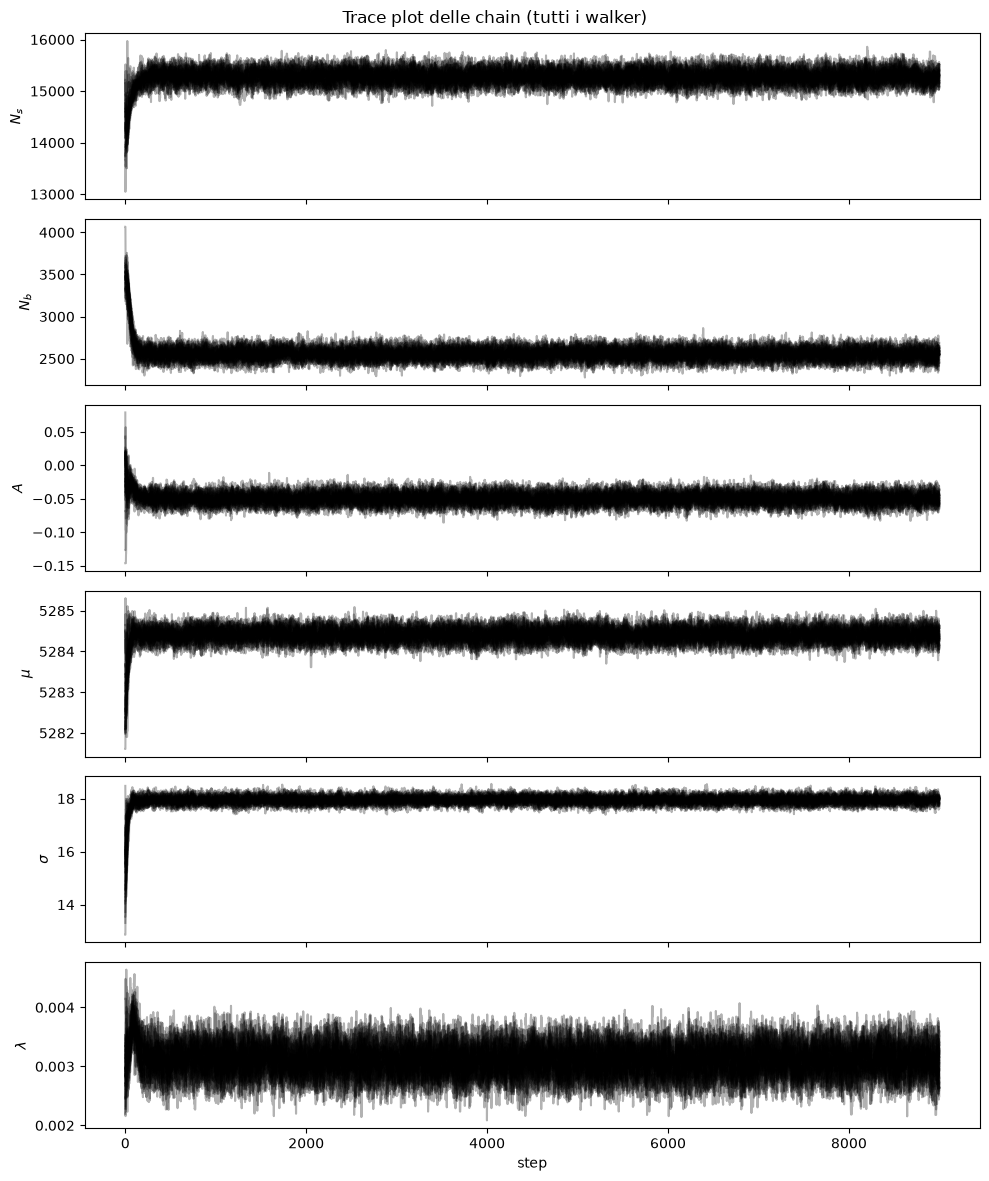

In [8]:
try:
    tau = sampler.get_autocorr_time()
    print("autocorrelation time per parametro:")
    for name, t in zip(bm.PARAM_NAMES, tau):
        print(f"  {name:12s} tau={t:.1f}  (n_eff ~= {nsteps*nwalkers/t:.0f})")
except emcee.autocorr.AutocorrError as e:
    print("Warning: catena forse troppo corta per una stima affidabile di tau:", e)

fig, axes = plt.subplots(ndim, figsize=(10, 12), sharex=True)
chain = sampler.get_chain()
for i in range(ndim):
    axes[i].plot(chain[:, :, i], alpha=0.3, color="k")
    axes[i].set_ylabel(bm.PARAM_LABELS[i])
axes[-1].set_xlabel("step")
fig.suptitle("Trace plot delle chain (tutti i walker)")
plt.tight_layout()
plt.show()

In [9]:
discard = nsteps // 6  # ~1/6 di burn-in, idioma confermato nelle esercitazioni del corso
flat_samples = sampler.get_chain(discard=discard, flat=True)
print(f"discarded first {discard} steps as burn-in, {len(flat_samples)} samples remaining")

discarded first 1500 steps as burn-in, 240000 samples remaining


## Output bayesiani

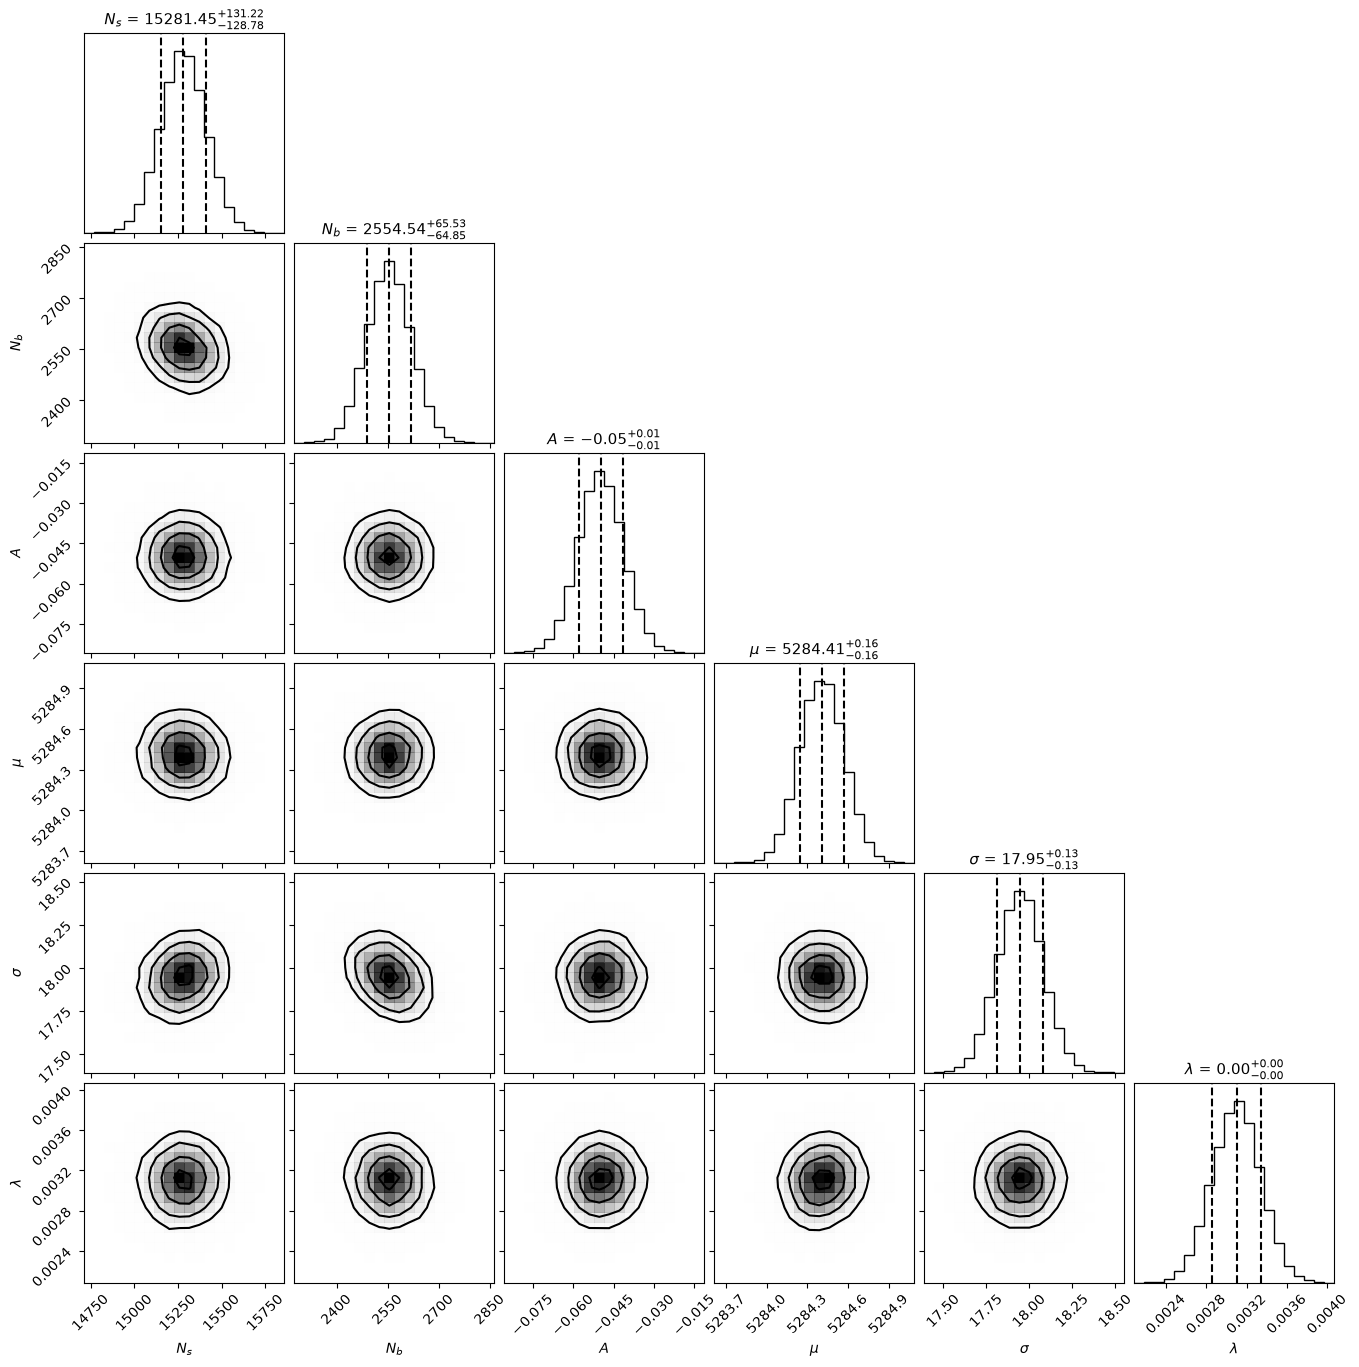

In [10]:
fig = corner.corner(
    flat_samples,
    labels=bm.PARAM_LABELS,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    plot_datapoints=False,
    title_kwargs={"fontsize": 11},
)
plt.show()

In [11]:
A_samples = flat_samples[:, bm.PARAM_NAMES.index("A")]
A_median = np.median(A_samples)
ci68 = np.percentile(A_samples, [16, 84])
ci95 = np.percentile(A_samples, [2.5, 97.5])

print(f"A_raw (posterior median) = {A_median:.4f}")
print(f"  68% credible interval: [{ci68[0]:.4f}, {ci68[1]:.4f}]")
print(f"  95% credible interval: [{ci95[0]:.4f}, {ci95[1]:.4f}]")

checkpoint_save("main_posterior_checkpoint", {
    "A_raw_median": float(A_median), "A_raw_ci68": [float(ci68[0]), float(ci68[1])],
    "A_raw_ci95": [float(ci95[0]), float(ci95[1])], "n_events": int(len(m_obs)),
})

A_raw (posterior median) = -0.0497
  68% credible interval: [-0.0579, -0.0413]
  95% credible interval: [-0.0659, -0.0331]
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/main_posterior_checkpoint.json


### Posterior predictive check

Curva del modello con i parametri al valore mediano del posterior, sovrapposta all'istogramma dei dati (separatamente per $B^+$ e $B^-$).

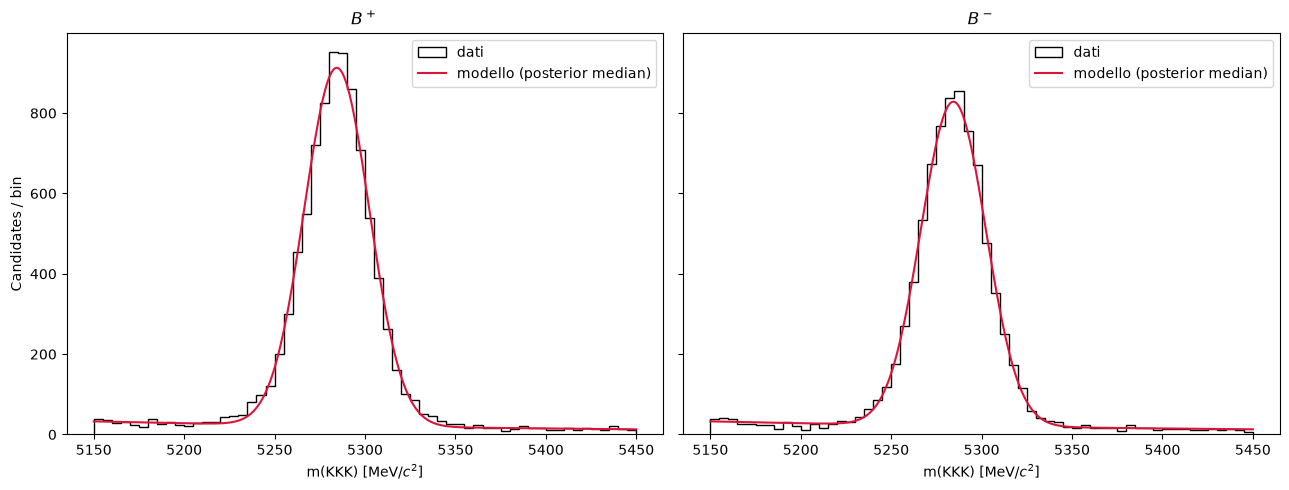

In [12]:
theta_med = np.median(flat_samples, axis=0)
N_s, N_b, A, mu, sigma, lam = theta_med
N_s_plus, N_s_minus, N_b_half = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2

m_grid = np.linspace(bm.MASS_LO, bm.MASS_HI, 300)
bin_width = bins[1] - bins[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, q_sign, N_s_q, label in (
    (axes[0], 1, N_s_plus, r"$B^+$"),
    (axes[1], -1, N_s_minus, r"$B^-$"),
):
    ax.hist(m_obs[q_obs == q_sign], bins=bins, histtype="step", color="k", label="dati")
    model_curve = (N_s_q * bm.signal_pdf(m_grid, mu, sigma) + N_b_half * bm.background_pdf(m_grid, lam)) * bin_width
    ax.plot(m_grid, model_curve, color="crimson", label="modello (posterior median)")
    ax.set_xlabel("m(KKK) [MeV/$c^2$]")
    ax.set_title(label)
    ax.legend()
axes[0].set_ylabel("Candidates / bin")
plt.tight_layout()
plt.show()

## Bayes factor: A = 0 vs A libero

Il metodo del corso (`Week4_BayesFactor.ipynb`) integra l'evidenza su una griglia 1D — non scala al nostro posterior a 6 parametri. Usiamo invece il **rapporto di Savage-Dickey**: $BF_{01} = p(A=0\mid\text{dati}) / \pi(A=0)$, stessa idea concettuale (rapporto di evidenze), adattata computazionalmente. La densità a posteriori in $A=0$ è stimata con una KDE sulla colonna $A$ della catena; la densità del prior è nota analiticamente ($1/2$, uniforme su $[-1,1]$). Assumiamo prior odds uguali fra $H_0$ ($A=0$) e $H_1$ ($A$ libero), quindi il Bayes factor coincide con gli odds a posteriori.

In [13]:
kde = gaussian_kde(A_samples)
posterior_density_at_0 = float(kde(0.0)[0])
prior_density_A = 1.0 / (bm.PRIOR_BOUNDS["A"][1] - bm.PRIOR_BOUNDS["A"][0])  # uniform prior density

BF_01 = posterior_density_at_0 / prior_density_A
print(f"posterior density of A at 0: {posterior_density_at_0:.3e}")
print(f"prior density of A at 0:     {prior_density_A:.4f}")
print(f"Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): {BF_01:.3e}")
print("(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)")
n_sigma_away = abs(0.0 - A_median) / A_samples.std()
print()
print(f"A=0 e' a ~{n_sigma_away:.1f} deviazioni standard del posterior dal valore osservato:")
print("la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,")
print("ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.")

posterior density of A at 0: 1.607e-59
prior density of A at 0:     0.5000
Savage-Dickey Bayes factor BF_01 (H0: A=0  vs  H1: A libero): 3.214e-59
(BF_01 > 1 favorisce H0/A=0; scala di Jeffreys: >3 evidenza moderata, >10 forte, >100 decisiva)

A=0 e' a ~6.0 deviazioni standard del posterior dal valore osservato:
la KDE sta estrapolando molto in coda -> il valore esatto di BF_01 e' numericamente fragile,
ma la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.


### Sensibilita' del Bayes factor al bandwidth della KDE

Verifica esplicita di quanto sia affidabile il numero appena calcolato: si ricalcola $BF_{01}$ variando il bandwidth della KDE (Silverman di default, poi scalato) senza rifare l'MCMC.

bandwidth x0.5 (silverman factor=0.0420): BF_01 = 2.500e-228
bandwidth x1.0 (silverman factor=0.0839): BF_01 = 3.214e-59
bandwidth x1.5 (silverman factor=0.1259): BF_01 = 5.048e-28
bandwidth x2.0 (silverman factor=0.1679): BF_01 = 3.618e-17
bandwidth x3.0 (silverman factor=0.2518): BF_01 = 1.681e-09


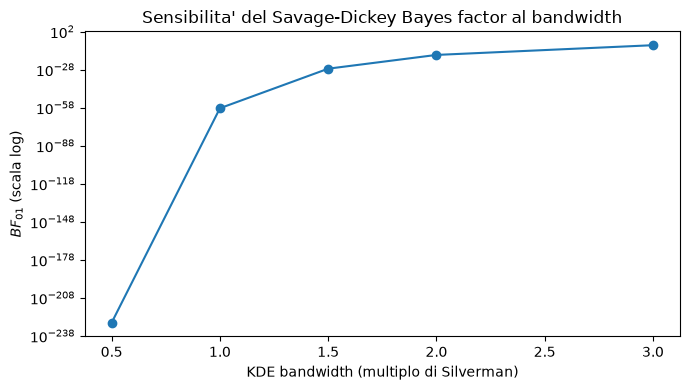


BF_01 varia di 6.7e+218 volte su questo range di bandwidth.
Conclusione: il VALORE ESATTO del Bayes factor non e' affidabile qui (A=0 e' troppo
in coda al posterior perche' Savage-Dickey via KDE funzioni bene). La conclusione
QUALITATIVA -- evidenza estrema/decisiva contro A=0 -- resta pero' robusta su tutto il range.


In [14]:
bw_multipliers = [0.5, 1.0, 1.5, 2.0, 3.0]
bf_vs_bw = []
for factor in bw_multipliers:
    kde_i = gaussian_kde(A_samples)
    kde_i.set_bandwidth(kde_i.factor * factor)
    dens0_i = float(kde_i(0.0)[0])
    bf_i = dens0_i / prior_density_A
    bf_vs_bw.append(bf_i)
    print(f"bandwidth x{factor:.1f} (silverman factor={kde_i.factor:.4f}): BF_01 = {bf_i:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(bw_multipliers, bf_vs_bw, "o-")
ax.set_xlabel("KDE bandwidth (multiplo di Silverman)")
ax.set_ylabel(r"$BF_{01}$ (scala log)")
ax.set_title("Sensibilita' del Savage-Dickey Bayes factor al bandwidth")
plt.tight_layout()
plt.show()

print()
print(f"BF_01 varia di {max(bf_vs_bw)/min(bf_vs_bw):.1e} volte su questo range di bandwidth.")
print("Conclusione: il VALORE ESATTO del Bayes factor non e' affidabile qui (A=0 e' troppo")
print("in coda al posterior perche' Savage-Dickey via KDE funzioni bene). La conclusione")
print("QUALITATIVA -- evidenza estrema/decisiva contro A=0 -- resta pero' robusta su tutto il range.")

In [ ]:
# A=0 e' a ~6 sd: la KDE non e' affidabile cosi' in coda. Il posterior marginale di A e' quasi gaussiano,
# quindi stimiamo la densita' in 0 con l'approssimazione gaussiana.
from scipy.stats import norm as _norm_bf
sd_A_post = float(np.std(A_samples))
BF_01_gauss = float(_norm_bf.pdf(0.0, np.mean(A_samples), sd_A_post) / prior_density_A)
print(f"approssimazione gaussiana: sd(A)={sd_A_post:.4f}, BF_01={BF_01_gauss:.2e}, ln BF_10={np.log(1/BF_01_gauss):.1f}")

## Cross-check: Magnet Up vs Magnet Down

Le due polarita' del magnete hanno asimmetrie di rivelazione opposte (pratica standard LHCb: sommarle le cancella parzialmente). Rifittiamo lo stesso modello separatamente sulle due polarita' e confrontiamo $A_{raw}$ -- se sono compatibili tra loro (e con il risultato combinato), e' un buon segno che l'asimmetria misurata non sia un artefatto strumentale di una singola polarita'. Catena piu' corta (5000 step) di quella principale: qui serve un confronto, non la precisione finale.

In [15]:
def fit_subset(m_sub, q_sub, label, nsteps_sub=5000, nwalkers_sub=32):
    theta0_sub = np.array([bm.INITIAL_GUESS[n] for n in bm.PARAM_NAMES])
    # scale the yield guesses to the subset size
    scale = len(m_sub) / len(m_obs)
    theta0_sub[0] *= scale  # N_s
    theta0_sub[1] *= scale  # N_b

    spread_sub = np.array([0.05*theta0_sub[0], 0.08*theta0_sub[1], 0.08, 1.5, 1.5, 0.2*theta0_sub[5]])
    pos_sub = theta0_sub + spread_sub * np.random.default_rng(7).standard_normal((nwalkers_sub, ndim))
    pos_sub[:, 2] = np.clip(pos_sub[:, 2], -0.5, 0.5)

    sampler_sub = emcee.EnsembleSampler(nwalkers_sub, ndim, bm.log_posterior, args=(m_sub, q_sub))
    sampler_sub.run_mcmc(pos_sub, nsteps_sub, progress=False)

    discard_sub = nsteps_sub // 6
    flat_sub = sampler_sub.get_chain(discard=discard_sub, flat=True)
    A_sub = flat_sub[:, bm.PARAM_NAMES.index("A")]
    med = float(np.median(A_sub))
    ci = [float(x) for x in np.percentile(A_sub, [16, 84])]
    acc = float(np.mean(sampler_sub.acceptance_fraction))
    print(f"{label}: n={len(m_sub)}  A_raw={med:.4f}  68% CI=[{ci[0]:.4f},{ci[1]:.4f}]  acceptance={acc:.2f}")
    return {"n": len(m_sub), "A_median": med, "A_ci68": ci, "acceptance": acc, "A_samples": A_sub}

mask_down = magnet_obs == "down"
mask_up = magnet_obs == "up"

result_down = fit_subset(m_obs[mask_down], q_obs[mask_down], "Magnet DOWN")
result_up = fit_subset(m_obs[mask_up], q_obs[mask_up], "Magnet UP")

diff = result_down["A_median"] - result_up["A_median"]
combined_unc = np.sqrt(np.diff(result_down["A_ci68"])[0]**2 + np.diff(result_up["A_ci68"])[0]**2) / 2
print(f"\ndifferenza A_raw(down) - A_raw(up) = {diff:.4f}  (~{abs(diff)/combined_unc:.1f} sigma combinate)")

checkpoint_save("magnet_updown_checkpoint", {
    "down": {"n": result_down["n"], "A_median": result_down["A_median"], "A_ci68": result_down["A_ci68"]},
    "up": {"n": result_up["n"], "A_median": result_up["A_median"], "A_ci68": result_up["A_ci68"]},
    "diff": float(diff),
})

Magnet DOWN: n=10500  A_raw=-0.0548  68% CI=[-0.0654,-0.0441]  acceptance=0.52


Magnet UP: n=7339  A_raw=-0.0426  68% CI=[-0.0558,-0.0298]  acceptance=0.52

differenza A_raw(down) - A_raw(up) = -0.0122  (~0.7 sigma combinate)
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/magnet_updown_checkpoint.json


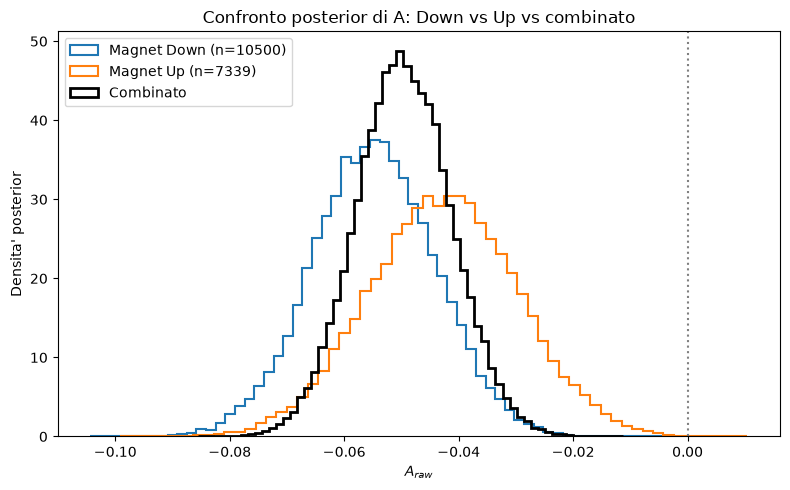

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(result_down["A_samples"], bins=60, density=True, histtype="step", label=f"Magnet Down (n={result_down['n']})", linewidth=1.5)
ax.hist(result_up["A_samples"], bins=60, density=True, histtype="step", label=f"Magnet Up (n={result_up['n']})", linewidth=1.5)
ax.hist(A_samples, bins=60, density=True, histtype="step", label="Combinato", color="k", linewidth=2)
ax.axvline(0, color="gray", linestyle=":")
ax.set_xlabel(r"$A_{raw}$")
ax.set_ylabel("Densita' posterior")
ax.legend()
ax.set_title("Confronto posterior di A: Down vs Up vs combinato")
plt.tight_layout()
plt.show()

## Cross-check: simmetria del fondo tra le cariche

Il modello assume $N_b^+=N_b^-=N_b/2$ (nessuna asimmetria di fondo), verificata finora solo indirettamente tramite il cross-check magnete. Qui la verifichiamo direttamente: nelle sidebands ($|m-\mu|>4\sigma$, dominate dal fondo combinatorio) calcoliamo l'asimmetria di conteggio -- se il fondo fosse davvero simmetrico tra le cariche ci aspettiamo un valore compatibile con zero.

In [17]:
mu_post = np.median(flat_samples[:, bm.PARAM_NAMES.index("mu")])
sigma_post = np.median(flat_samples[:, bm.PARAM_NAMES.index("sigma")])
side_gap_lo_bg, side_gap_hi_bg = mu_post - 4*sigma_post, mu_post + 4*sigma_post
is_sideband_bg = (m_obs < side_gap_lo_bg) | (m_obs > side_gap_hi_bg)

q_sb = q_obs[is_sideband_bg]
n_plus_sb, n_minus_sb = int(np.sum(q_sb == 1)), int(np.sum(q_sb == -1))
n_tot_sb = n_plus_sb + n_minus_sb
A_sb = (n_minus_sb - n_plus_sb) / n_tot_sb
sigma_A_sb = np.sqrt(max(1 - A_sb**2, 0) / n_tot_sb)
print(f"sidebands (|m-mu_post|>4sigma_post, fuori [{side_gap_lo_bg:.1f},{side_gap_hi_bg:.1f}] MeV): n={n_tot_sb}")
print(f"  n+ = {n_plus_sb}   n- = {n_minus_sb}")
print(f"  A_sideband = {A_sb:+.4f} +- {sigma_A_sb:.4f}  ({abs(A_sb)/sigma_A_sb:.2f} sigma da zero)")

lo_sb, hi_sb = m_obs < side_gap_lo_bg, m_obs > side_gap_hi_bg
for name, mask_sb in [("sideband bassa", lo_sb), ("sideband alta", hi_sb)]:
    qq = q_obs[mask_sb]
    npl, nmi = int(np.sum(qq == 1)), int(np.sum(qq == -1))
    ntot = npl + nmi
    A_ = (nmi - npl) / ntot if ntot > 0 else float("nan")
    sA_ = np.sqrt(max(1 - A_**2, 0) / ntot) if ntot > 0 else float("nan")
    print(f"  {name}: n={ntot} (n+={npl}, n-={nmi})  A={A_:+.4f} +- {sA_:.4f}")

checkpoint_save("sideband_symmetry_checkpoint", {
    "mu_post": float(mu_post), "sigma_post": float(sigma_post),
    "n_sideband": n_tot_sb, "n_plus": n_plus_sb, "n_minus": n_minus_sb,
    "A_sideband": float(A_sb), "sigma_A_sideband": float(sigma_A_sb),
})

sidebands (|m-mu_post|>4sigma_post, fuori [5212.6,5356.2] MeV): n=1217
  n+ = 637   n- = 580
  A_sideband = -0.0468 +- 0.0286  (1.64 sigma da zero)
  sideband bassa: n=689 (n+=359, n-=330)  A=-0.0421 +- 0.0381
  sideband alta: n=528 (n+=278, n-=250)  A=-0.0530 +- 0.0435
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/sideband_symmetry_checkpoint.json


### Fit con fondo libero per carica

Invece di assumere $N_b^+=N_b^-$, si lascia libera l'asimmetria del fondo: $N_b^\pm = N_b(1\mp A_b)/2$, con prior uniforme $A_b\in(-1,1)$. Stesso sampler e stessa lunghezza della catena nominale.

In [ ]:
plus_obs = q_obs > 0

def log_posterior_free_bkg(theta):
    N_s_, N_b_, A_, A_b_, mu_, sig_, lam_ = theta
    N = len(m_obs)
    if not (0 < N_s_ < 5*N and 0 < N_b_ < 5*N and -1 < A_ < 1 and -1 < A_b_ < 1
            and 5260 < mu_ < 5310 and 3 < sig_ < 40 and 1e-5 < lam_ < 0.05):
        return -np.inf
    s_ = bm.signal_pdf(m_obs, mu_, sig_); b_ = bm.background_pdf(m_obs, lam_)
    dp = N_s_*(1-A_)/2*s_[plus_obs] + N_b_*(1-A_b_)/2*b_[plus_obs]
    dm = N_s_*(1+A_)/2*s_[~plus_obs] + N_b_*(1+A_b_)/2*b_[~plus_obs]
    if np.any(dp <= 0) or np.any(dm <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s_ + N_b_)

theta0_fb = np.array([15281., 2555., -0.05, 0.0, 5284.4, 17.95, 0.0031])
spread_fb = np.array([0.03*theta0_fb[0], 0.05*theta0_fb[1], 0.05, 0.05, 1.0, 1.0, 0.15*theta0_fb[6]])
pos_fb = theta0_fb + spread_fb * np.random.default_rng(42).standard_normal((32, 7))
sampler_fb = emcee.EnsembleSampler(32, 7, log_posterior_free_bkg)
sampler_fb.run_mcmc(pos_fb, 9000, progress=False)
flat_fb = sampler_fb.get_chain(discard=1500, flat=True)
tau_fb = sampler_fb.get_autocorr_time(discard=1500, quiet=True)

A_fb, Ab_fb = flat_fb[:, 2], flat_fb[:, 3]
from scipy.stats import norm as _norm_fb
BF_10_Ab = float(0.5 / _norm_fb.pdf(0.0, np.mean(Ab_fb), np.std(Ab_fb)))  # Savage-Dickey, approx. gaussiana
free_bkg_summary = {
    "A_median": float(np.median(A_fb)), "A_ci68": [float(x) for x in np.percentile(A_fb, [16, 84])],
    "A_b_median": float(np.median(Ab_fb)), "A_b_sd": float(np.std(Ab_fb)),
    "A_b_ci68": [float(x) for x in np.percentile(Ab_fb, [16, 84])],
    "corr_A_Ab": float(np.corrcoef(A_fb, Ab_fb)[0, 1]), "BF_10_Ab": BF_10_Ab,
    "acceptance": float(np.mean(sampler_fb.acceptance_fraction)), "tau_max": float(np.max(tau_fb)),
}
print(f"fondo libero: A = {free_bkg_summary['A_median']:.4f}  68% CI={free_bkg_summary['A_ci68']}")
print(f"              A_b = {free_bkg_summary['A_b_median']:.3f} +- {free_bkg_summary['A_b_sd']:.3f} "
      f"({abs(free_bkg_summary['A_b_median'])/free_bkg_summary['A_b_sd']:.1f} sigma da zero), BF_10={BF_10_Ab:.1f}")
print(f"              spostamento di A rispetto al nominale: {free_bkg_summary['A_median'] - A_median:+.4f}")
checkpoint_save("free_background_checkpoint", free_bkg_summary)

### Catene da punti di partenza dispersi

Le slide (Week 4, "Common pitfalls of MCMC") raccomandano più catene indipendenti da punti diversi. Ripetiamo il fit nominale due volte con i 32 walker distribuiti uniformemente su tutto il box del prior.

In [ ]:
lo_box = np.array([bm.PRIOR_BOUNDS[n][0] for n in bm.PARAM_NAMES])
hi_box = np.array([bm.PRIOR_BOUNDS[n][1] for n in bm.PARAM_NAMES])
dispersed_summary = []
for seed_d in (1, 2):
    pos_d = lo_box + (hi_box - lo_box) * np.random.default_rng(seed_d).uniform(0.02, 0.98, (nwalkers, ndim))
    sampler_d = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_obs, q_obs))
    sampler_d.run_mcmc(pos_d, nsteps, progress=False)
    chain_d = sampler_d.get_chain()
    in_bulk = (np.abs(chain_d[:, :, 2] - A_median) < 5 * np.std(A_samples)).all(axis=1)
    steps_to_bulk = int(np.argmax(in_bulk)) if in_bulk.any() else -1
    A_d = sampler_d.get_chain(discard=discard, flat=True)[:, 2]
    r_d = {"seed": seed_d, "steps_to_bulk": steps_to_bulk, "A_median": float(np.median(A_d)),
           "A_ci68": [float(x) for x in np.percentile(A_d, [16, 84])]}
    dispersed_summary.append(r_d)
    print(f"seed {seed_d}: walker nel bulk dopo {steps_to_bulk} step; A = {r_d['A_median']:.4f}  68% CI={r_d['A_ci68']}")
print(f"nominale: A = {A_median:.4f}  68% CI=[{ci68[0]:.4f},{ci68[1]:.4f}]")
checkpoint_save("dispersed_start_checkpoint", {"runs": dispersed_summary})

### Veto sulle risonanze di charm

$B^\pm\to D^0K^\pm$, $J/\psi K^\pm$, $\chi_{c0}K^\pm$ con $D^0, J/\psi, \chi_{c0}\to K^+K^-$ non sono charmless. Escludiamo i candidati con almeno una coppia di carica opposta entro $\pm30$ MeV dalla massa della risonanza e ripetiamo il fit nominale.

In [ ]:
ch_v = data[["H1_Charge", "H2_Charge", "H3_Charge"]].to_numpy()
bach_v = np.argmax(ch_v != np.sign(data["B_Charge"].to_numpy())[:, None], axis=1)
same_v = np.array([[j for j in range(3) if j != b] for b in bach_v])
E_v = data[["H1_E", "H2_E", "H3_E"]].to_numpy(); PX_v = data[["H1_PX", "H2_PX", "H3_PX"]].to_numpy()
PY_v = data[["H1_PY", "H2_PY", "H3_PY"]].to_numpy(); PZ_v = data[["H1_PZ", "H2_PZ", "H3_PZ"]].to_numpy()
r_v = np.arange(len(data))

def m_pair_v(i, j):
    return np.sqrt(np.clip((E_v[r_v, i] + E_v[r_v, j])**2 - (PX_v[r_v, i] + PX_v[r_v, j])**2
                           - (PY_v[r_v, i] + PY_v[r_v, j])**2 - (PZ_v[r_v, i] + PZ_v[r_v, j])**2, 0, None))

m_a_v, m_b_v = m_pair_v(bach_v, same_v[:, 0]), m_pair_v(bach_v, same_v[:, 1])

charm_veto_summary = {}
for label_v, states_v in (("D0", [1864.84]), ("D0_Jpsi_chic0", [1864.84, 3096.9, 3414.7])):
    veto_v = np.zeros(len(data), bool)
    for m0 in states_v:
        veto_v |= (np.abs(m_a_v - m0) < 30) | (np.abs(m_b_v - m0) < 30)
    m_k, q_k = m_obs[~veto_v], q_obs[~veto_v]
    th0_v = theta0.copy(); th0_v[:2] *= len(m_k) / len(m_obs)
    sp_v = np.array([0.03*th0_v[0], 0.05*th0_v[1], 0.05, 1.0, 1.0, 0.15*th0_v[5]])
    pos_v = th0_v + sp_v * np.random.default_rng(42).standard_normal((nwalkers, ndim))
    pos_v[:, 2] = np.clip(pos_v[:, 2], -0.5, 0.5)
    sampler_vt = emcee.EnsembleSampler(nwalkers, ndim, bm.log_posterior, args=(m_k, q_k))
    sampler_vt.run_mcmc(pos_v, nsteps, progress=False)
    A_vt = sampler_vt.get_chain(discard=discard, flat=True)[:, 2]
    q_rm = q_obs[veto_v]
    charm_veto_summary[label_v] = {
        "n_kept": int(len(m_k)), "n_removed": int(veto_v.sum()),
        "A_count_removed": float((np.sum(q_rm < 0) - np.sum(q_rm > 0)) / max(len(q_rm), 1)),
        "A_median": float(np.median(A_vt)), "A_ci68": [float(x) for x in np.percentile(A_vt, [16, 84])]}
    print(f"veto {label_v}: rimossi {veto_v.sum()}, A = {charm_veto_summary[label_v]['A_median']:.4f}  "
          f"68% CI={charm_veto_summary[label_v]['A_ci68']}  "
          f"(spostamento {charm_veto_summary[label_v]['A_median'] - A_median:+.4f})")
checkpoint_save("charm_veto_checkpoint", charm_veto_summary)

## Toy-MC coverage check

Genera pseudo-dataset campionando dal modello *fittato* (parametric bootstrap, stessa dimensione del dataset reale), inietta il valore vero $A_{\rm true}$ = valore osservato, rifitta con una catena piu' corta, e verifica quante volte il credible interval 68% contiene $A_{\rm true}$. Se la copertura empirica e' vicina al 68% nominale, gli intervalli di credibilita' riportati sopra sono affidabili; se e' molto piu' bassa, sono troppo stretti (overconfident).

In [18]:
def sample_truncated_exponential(rng, lam, lo, hi, n):
    u = rng.uniform(0, 1, n)
    W = hi - lo
    return lo - np.log(1 - u * (1 - np.exp(-lam * W))) / lam

def sample_truncated_normal(rng, mu, sigma, lo, hi, n):
    from scipy.stats import truncnorm
    a, b = (lo - mu) / sigma, (hi - mu) / sigma
    return truncnorm.rvs(a, b, loc=mu, scale=sigma, size=n, random_state=rng)

def generate_toy(rng, theta_true):
    N_s, N_b, A, mu, sigma, lam = theta_true
    N_s_plus = rng.poisson(N_s * (1 - A) / 2)
    N_s_minus = rng.poisson(N_s * (1 + A) / 2)
    N_b_plus = rng.poisson(N_b / 2)
    N_b_minus = rng.poisson(N_b / 2)

    m_sp = sample_truncated_normal(rng, mu, sigma, bm.MASS_LO, bm.MASS_HI, N_s_plus)
    m_sm = sample_truncated_normal(rng, mu, sigma, bm.MASS_LO, bm.MASS_HI, N_s_minus)
    m_bp = sample_truncated_exponential(rng, lam, bm.MASS_LO, bm.MASS_HI, N_b_plus)
    m_bm = sample_truncated_exponential(rng, lam, bm.MASS_LO, bm.MASS_HI, N_b_minus)

    m_toy = np.concatenate([m_sp, m_sm, m_bp, m_bm])
    q_toy = np.concatenate([np.full(N_s_plus, 1), np.full(N_s_minus, -1),
                             np.full(N_b_plus, 1), np.full(N_b_minus, -1)])
    return m_toy, q_toy

theta_true = theta_med.copy()  # inject the observed posterior median as ground truth
print("theta_true used for toy generation:", dict(zip(bm.PARAM_NAMES, theta_true)))

theta_true used for toy generation: {'N_s': np.float64(15281.451208062927), 'N_b': np.float64(2554.541047168116), 'A': np.float64(-0.04972502482826961), 'mu': np.float64(5284.409866809464), 'sigma': np.float64(17.948108073420144), 'lambda_bkg': np.float64(0.0031029873771233852)}


In [19]:
N_TOYS = 500
NSTEPS_TOY = 3500
NWALKERS_TOY = 32

rng = np.random.default_rng(123)
covered_68 = 0
covered_95 = 0
toy_A_medians = []

for i in range(N_TOYS):
    m_toy, q_toy = generate_toy(rng, theta_true)

    spread_toy = np.array([0.05*theta_true[0], 0.08*theta_true[1], 0.08, 1.5, 1.5, 0.2*theta_true[5]])
    pos_toy = theta_true + spread_toy * rng.standard_normal((NWALKERS_TOY, ndim))
    pos_toy[:, 2] = np.clip(pos_toy[:, 2], -0.9, 0.9)

    sampler_toy = emcee.EnsembleSampler(NWALKERS_TOY, ndim, bm.log_posterior, args=(m_toy, q_toy))
    sampler_toy.run_mcmc(pos_toy, NSTEPS_TOY, progress=False)

    flat_toy = sampler_toy.get_chain(discard=NSTEPS_TOY // 6, flat=True)
    A_toy = flat_toy[:, bm.PARAM_NAMES.index("A")]
    ci68_toy = np.percentile(A_toy, [16, 84])
    ci95_toy = np.percentile(A_toy, [2.5, 97.5])
    toy_A_medians.append(np.median(A_toy))

    in68 = ci68_toy[0] <= theta_true[2] <= ci68_toy[1]
    in95 = ci95_toy[0] <= theta_true[2] <= ci95_toy[1]
    covered_68 += in68
    covered_95 += in95
    print(f"toy {i+1:2d}/{N_TOYS}: A_hat={np.median(A_toy):+.4f}  68% CI=[{ci68_toy[0]:+.4f},{ci68_toy[1]:+.4f}]  "
          f"in68={in68}  in95={in95}")
    if (i + 1) % 5 == 0 or (i + 1) == N_TOYS:
        checkpoint_save("toy_mc_coverage_progress", {
            "n_done": i + 1, "n_total": N_TOYS,
            "coverage_68_so_far": covered_68 / (i + 1), "coverage_95_so_far": covered_95 / (i + 1),
            "toy_A_medians_so_far": toy_A_medians,
        })

cov68_frac = covered_68 / N_TOYS
cov95_frac = covered_95 / N_TOYS
print(f"\nempirical 68% coverage: {covered_68}/{N_TOYS} = {cov68_frac:.2f} (nominale: 0.68)")
print(f"empirical 95% coverage: {covered_95}/{N_TOYS} = {cov95_frac:.2f} (nominale: 0.95)")
checkpoint_save("toy_mc_coverage_final", {
    "n_toys": N_TOYS, "coverage_68": cov68_frac, "coverage_95": cov95_frac,
    "toy_A_medians": toy_A_medians,
})

toy  1/500: A_hat=-0.0554  68% CI=[-0.0632,-0.0471]  in68=True  in95=True


toy  2/500: A_hat=-0.0731  68% CI=[-0.0811,-0.0645]  in68=False  in95=False


toy  3/500: A_hat=-0.0443  68% CI=[-0.0524,-0.0361]  in68=True  in95=True


toy  4/500: A_hat=-0.0476  68% CI=[-0.0558,-0.0392]  in68=True  in95=True


toy  5/500: A_hat=-0.0421  68% CI=[-0.0505,-0.0339]  in68=True  in95=True
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/toy_mc_coverage_progress.json


...

toy 496/500: A_hat=-0.0431  68% CI=[-0.0513,-0.0349]  in68=True  in95=True


toy 497/500: A_hat=-0.0496  68% CI=[-0.0578,-0.0411]  in68=True  in95=True


toy 498/500: A_hat=-0.0494  68% CI=[-0.0578,-0.0411]  in68=True  in95=True


toy 499/500: A_hat=-0.0485  68% CI=[-0.0569,-0.0402]  in68=True  in95=True


toy 500/500: A_hat=-0.0466  68% CI=[-0.0547,-0.0385]  in68=True  in95=True
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/toy_mc_coverage_progress.json

empirical 68% coverage: 332/500 = 0.66 (nominale: 0.68)
empirical 95% coverage: 481/500 = 0.96 (nominale: 0.95)
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/toy_mc_coverage_final.json


In [ ]:
# bias e dispersione delle stime nei toy, confrontate con la sd del posterior sui dati
toy_arr = np.array(toy_A_medians)
toy_bias = float(toy_arr.mean() - theta_true[bm.PARAM_NAMES.index("A")])
toy_bias_err = float(toy_arr.std(ddof=1) / np.sqrt(len(toy_arr)))
toy_sd = float(toy_arr.std(ddof=1))
print(f"bias = {toy_bias:+.5f} +- {toy_bias_err:.5f}; sd delle stime = {toy_sd:.5f} vs sd posterior dati = {np.std(A_samples):.5f}")

## Studio sistematico

Verifica di quanto $A_{raw}$ cambia sotto scelte di modellazione alternative (stessa idea della riga "Systematic Uncertainties" nella proposta). Stessa lunghezza di catena della fit nominale (9000 step, 32 walker) -- inizialmente accorciata a 2500 step/24 walker per velocita', poi allungata a catena piena per una conferma definitiva (vedi "Limiti noti"). Funzioni di pdf locali, parametrizzate esplicitamente su una finestra $[lo,hi]$, per non toccare le costanti globali di `bayesian_model.py`.

In [20]:
from scipy.stats import norm as _norm_syst

def signal_pdf_w(m, mu, sigma, lo, hi):
    norm_const = _norm_syst.cdf(hi, mu, sigma) - _norm_syst.cdf(lo, mu, sigma)
    return _norm_syst.pdf(m, mu, sigma) / norm_const

def background_pdf_exp_w(m, lam, lo, hi):
    num = lam * np.exp(-lam * (m - lo))
    den = 1.0 - np.exp(-lam * (hi - lo))
    return num / den

def background_pdf_lin_w(m, c, lo, hi):
    # c in (-1, 1): linear shape, guaranteed positive on [lo, hi]
    x = 2 * (m - lo) / (hi - lo) - 1  # maps [lo,hi] -> [-1,1]
    return (1 + c * x) / (hi - lo)

def log_posterior_syst(theta, m, q, lo, hi, bkg="exp", A_bound=1.0):
    N_s, N_b, A, mu, sigma, bkg_par = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-A_bound < A < A_bound): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if bkg == "exp":
        if not (1e-5 < bkg_par < 0.05): return -np.inf
        b = background_pdf_exp_w(m, bkg_par, lo, hi)
    else:
        if not (-0.99 < bkg_par < 0.99): return -np.inf
        b = background_pdf_lin_w(m, bkg_par, lo, hi)

    s = signal_pdf_w(m, mu, sigma, lo, hi)
    N_s_plus, N_s_minus, N_b_half = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus = q > 0
    dens_plus = N_s_plus*s[is_plus] + N_b_half*b[is_plus]
    dens_minus = N_s_minus*s[~is_plus] + N_b_half*b[~is_plus]
    if np.any(dens_plus <= 0) or np.any(dens_minus <= 0):
        return -np.inf
    ll = np.sum(np.log(dens_plus)) + np.sum(np.log(dens_minus)) - (N_s + N_b)
    return ll

def fit_variation(label, lo, hi, bkg="exp", A_bound=1.0, nsteps_v=9000, nwalkers_v=32):
    win_mask = (data.B_M > lo) & (data.B_M < hi)
    m_v = data.B_M.to_numpy()[win_mask]
    q_v = data.B_Charge.to_numpy()[win_mask]

    bkg_guess = bm.INITIAL_GUESS["lambda_bkg"] if bkg == "exp" else 0.0
    theta0_v = np.array([bm.INITIAL_GUESS["N_s"]*len(m_v)/len(m_obs), bm.INITIAL_GUESS["N_b"]*len(m_v)/len(m_obs),
                          0.0, bm.INITIAL_GUESS["mu"], bm.INITIAL_GUESS["sigma"], bkg_guess])
    spread_v = np.array([0.05*theta0_v[0], 0.08*theta0_v[1], 0.05, 1.5, 1.5,
                          0.2*bm.INITIAL_GUESS["lambda_bkg"] if bkg=="exp" else 0.1])
    pos_v = theta0_v + spread_v * np.random.default_rng(11).standard_normal((nwalkers_v, len(theta0_v)))
    pos_v[:, 2] = np.clip(pos_v[:, 2], -min(0.5, A_bound*0.9), min(0.5, A_bound*0.9))

    sampler_v = emcee.EnsembleSampler(nwalkers_v, len(theta0_v), log_posterior_syst,
                                        args=(m_v, q_v, lo, hi, bkg, A_bound))
    sampler_v.run_mcmc(pos_v, nsteps_v, progress=False)
    flat_v = sampler_v.get_chain(discard=nsteps_v//6, flat=True)
    A_v = flat_v[:, 2]
    med_v = float(np.median(A_v))
    ci_v = [float(x) for x in np.percentile(A_v, [16, 84])]
    print(f"{label:32s} n={len(m_v):6d}  A_raw={med_v:+.4f}  68% CI=[{ci_v[0]:+.4f},{ci_v[1]:+.4f}]")
    return {"label": label, "n": len(m_v), "A_median": med_v, "A_ci68": ci_v}

syst_results = [{"label": "Nominale (5150-5450, exp bkg)", "n": len(m_obs), "A_median": A_median, "A_ci68": [float(ci68[0]), float(ci68[1])]}]
syst_results.append(fit_variation("Finestra stretta (5200-5450)", 5200.0, 5450.0))
syst_results.append(fit_variation("Finestra corta in alto (5150-5400)", 5150.0, 5400.0))
syst_results.append(fit_variation("Fondo lineare (5150-5450)", 5150.0, 5450.0, bkg="lin"))
syst_results.append(fit_variation("Prior A stretto [-0.3,0.3] (5150-5450)", 5150.0, 5450.0, A_bound=0.3))

checkpoint_save("systematic_study_checkpoint", syst_results)

Finestra stretta (5200-5450)     n= 17267  A_raw=-0.0497  68% CI=[-0.0580,-0.0413]


Finestra corta in alto (5150-5400) n= 17590  A_raw=-0.0498  68% CI=[-0.0581,-0.0415]


Fondo lineare (5150-5450)        n= 17839  A_raw=-0.0498  68% CI=[-0.0581,-0.0415]


Prior A stretto [-0.3,0.3] (5150-5450) n= 17839  A_raw=-0.0495  68% CI=[-0.0577,-0.0414]
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/systematic_study_checkpoint.json


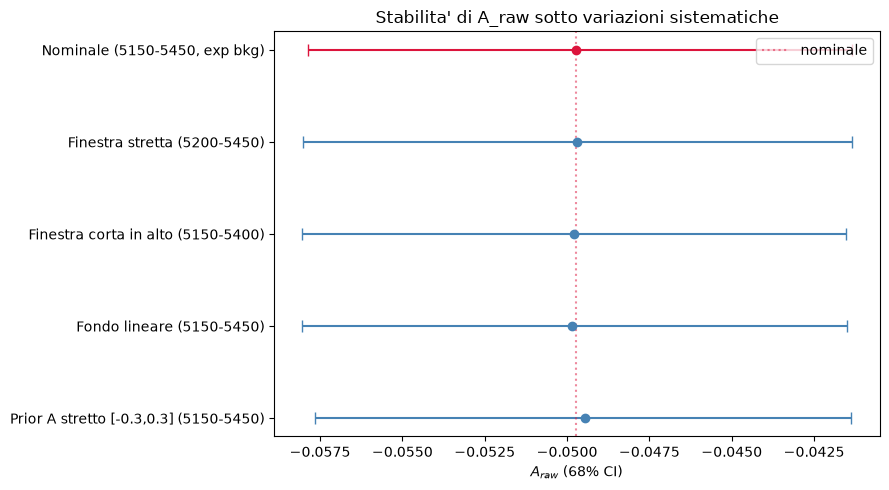

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
ys = list(range(len(syst_results)))[::-1]
for y, r in zip(ys, syst_results):
    med, (lo_ci, hi_ci) = r["A_median"], r["A_ci68"]
    ax.errorbar(med, y, xerr=[[med-lo_ci], [hi_ci-med]], fmt="o", capsize=4,
                color="crimson" if "Nominale" in r["label"] else "steelblue")
ax.set_yticks(ys)
ax.set_yticklabels([r["label"] for r in syst_results])
ax.axvline(A_median, color="crimson", linestyle=":", alpha=0.5, label="nominale")
ax.set_xlabel(r"$A_{raw}$ (68% CI)")
ax.set_title("Stabilita' di A_raw sotto variazioni sistematiche")
ax.legend()
plt.tight_layout()
plt.show()

## Goodness-of-fit del modello (nominale)

Pull binned: $(\text{osservato} - \text{atteso})/\sqrt{\text{atteso}}$ per bin, separatamente per $B^+$ e $B^-$, con $\chi^2$/ndof come sintesi numerica del posterior predictive check già visto qualitativamente sopra.

B+ : chi2 = 80.4 over 30 bins
B- : chi2 = 47.1 over 30 bins
Totale: chi2/ndof = 127.4 / 54 = 2.36
(vicino a 1 = buon accordo; se molto maggiore di 1 il modello minimale non basta)


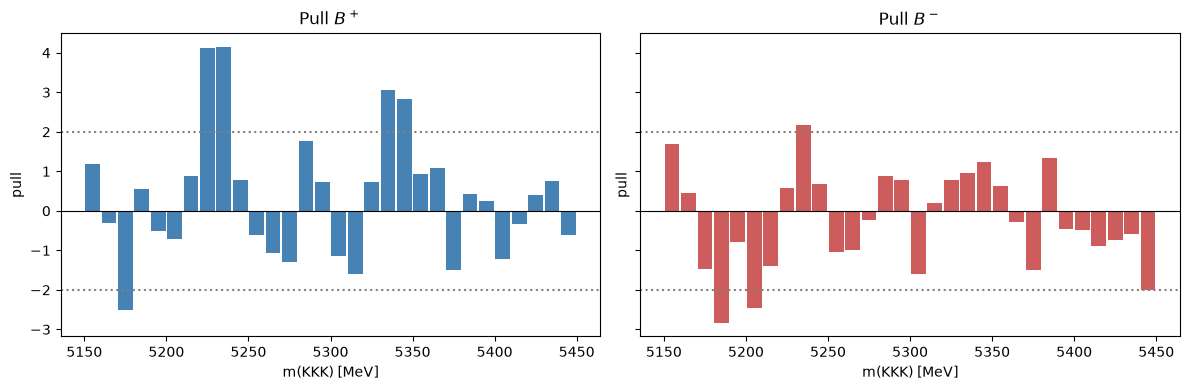

In [22]:
def binned_gof(m_data, bin_edges, N_s_q, N_b_half, mu, sigma, lam):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * bm.signal_pdf(centers, mu, sigma) + N_b_half * bm.background_pdf(centers, lam)) * bw
    pull = (obs - exp) / np.sqrt(np.maximum(exp, 1e-9))
    chi2 = np.sum(pull**2)
    return obs, exp, pull, chi2

gof_bins = np.linspace(bm.MASS_LO, bm.MASS_HI, 31)  # coarser binning for stable expected counts
obs_p, exp_p, pull_p, chi2_p = binned_gof(m_obs[q_obs > 0], gof_bins, N_s_plus, N_b_half, mu, sigma, lam)
obs_m, exp_m, pull_m, chi2_m = binned_gof(m_obs[q_obs < 0], gof_bins, N_s_minus, N_b_half, mu, sigma, lam)

ndof = 2 * (len(gof_bins) - 1) - ndim  # both charge samples, minus fitted parameters
chi2_tot = chi2_p + chi2_m
print(f"B+ : chi2 = {chi2_p:.1f} over {len(gof_bins)-1} bins")
print(f"B- : chi2 = {chi2_m:.1f} over {len(gof_bins)-1} bins")
print(f"Totale: chi2/ndof = {chi2_tot:.1f} / {ndof} = {chi2_tot/ndof:.2f}")
print("(vicino a 1 = buon accordo; se molto maggiore di 1 il modello minimale non basta)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
centers = 0.5 * (gof_bins[:-1] + gof_bins[1:])
axes[0].bar(centers, pull_p, width=(gof_bins[1]-gof_bins[0])*0.9, color="steelblue")
axes[0].set_title(r"Pull $B^+$"); axes[0].axhline(0, color="k", lw=0.8)
axes[1].bar(centers, pull_m, width=(gof_bins[1]-gof_bins[0])*0.9, color="indianred")
axes[1].set_title(r"Pull $B^-$"); axes[1].axhline(0, color="k", lw=0.8)
for ax in axes:
    ax.set_xlabel("m(KKK) [MeV]"); ax.set_ylabel("pull")
    ax.axhline(2, color="gray", ls=":"); ax.axhline(-2, color="gray", ls=":")
plt.tight_layout()
plt.show()

## Modello di segnale alternativo: Crystal Ball

Il $\chi^2$/ndof sopra non è vicino a 1: il modello gaussiana pura è troppo semplice. Proviamo una **Crystal Ball** (gaussiana con coda a potenza sul lato di massa bassa, tipica delle perdite radiative in fisica del B, coerente con l'approccio del paper di riferimento che usa Gaussiana + due Crystal Ball). I parametri di forma della coda ($\beta$, $m$) sono fissati a valori tipici di letteratura ($\beta=1.5$, $m=3$) invece di essere fittati, per non aumentare la dimensionalità del problema (restiamo a 6 parametri, stesso setup MCMC) -- è una scelta di semplicità dichiarata, non un fit completo alla paper.

In [23]:
from scipy.stats import crystalball as _cb

CB_BETA, CB_M = 1.5, 3.0  # fissati, non fittati

def signal_pdf_cb(m, mu, sigma, lo, hi):
    norm_const = _cb.cdf((hi - mu) / sigma, CB_BETA, CB_M) - _cb.cdf((lo - mu) / sigma, CB_BETA, CB_M)
    return _cb.pdf((m - mu) / sigma, CB_BETA, CB_M) / sigma / norm_const

def log_posterior_cb(theta, m, q, lo, hi):
    N_s, N_b, A, mu, sigma, lam = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-1 < A < 1): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if not (1e-5 < lam < 0.05): return -np.inf

    s = signal_pdf_cb(m, mu, sigma, lo, hi)
    b = background_pdf_exp_w(m, lam, lo, hi)
    N_s_plus_, N_s_minus_, N_b_half_ = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus_ = q > 0
    dp = N_s_plus_*s[is_plus_] + N_b_half_*b[is_plus_]
    dm = N_s_minus_*s[~is_plus_] + N_b_half_*b[~is_plus_]
    if np.any(dp <= 0) or np.any(dm <= 0):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s + N_b)

theta0_cb = theta0.copy()
spread_cb = np.array([0.03*theta0_cb[0], 0.05*theta0_cb[1], 0.05, 1.0, 1.0, 0.15*theta0_cb[5]])
pos_cb = theta0_cb + spread_cb * np.random.default_rng(99).standard_normal((nwalkers, ndim))
pos_cb[:, 2] = np.clip(pos_cb[:, 2], -0.5, 0.5)

sampler_cb = emcee.EnsembleSampler(nwalkers, ndim, log_posterior_cb, args=(m_obs, q_obs, bm.MASS_LO, bm.MASS_HI))
sampler_cb.run_mcmc(pos_cb, 6000, progress=True)

flat_cb = sampler_cb.get_chain(discard=1000, flat=True)
A_cb = flat_cb[:, 2]
A_median_cb = float(np.median(A_cb))
ci68_cb = [float(x) for x in np.percentile(A_cb, [16, 84])]
print(f"\nCrystal Ball:  A_raw = {A_median_cb:.4f}  68% CI=[{ci68_cb[0]:.4f},{ci68_cb[1]:.4f}]  "
      f"acceptance={np.mean(sampler_cb.acceptance_fraction):.2f}")

theta_med_cb = np.median(flat_cb, axis=0)
N_s_cb, N_b_cb, A_cb_med, mu_cb, sigma_cb, lam_cb = theta_med_cb
N_s_plus_cb, N_s_minus_cb, N_b_half_cb = N_s_cb*(1-A_cb_med)/2, N_s_cb*(1+A_cb_med)/2, N_b_cb/2

def binned_gof_cb(m_data, bin_edges, N_s_q, N_b_half_, mu_, sigma_, lam_):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * signal_pdf_cb(centers, mu_, sigma_, bm.MASS_LO, bm.MASS_HI)
           + N_b_half_ * background_pdf_exp_w(centers, lam_, bm.MASS_LO, bm.MASS_HI)) * bw
    return np.sum((obs - exp)**2 / np.maximum(exp, 1e-9))

chi2_cb = (binned_gof_cb(m_obs[q_obs > 0], gof_bins, N_s_plus_cb, N_b_half_cb, mu_cb, sigma_cb, lam_cb)
           + binned_gof_cb(m_obs[q_obs < 0], gof_bins, N_s_minus_cb, N_b_half_cb, mu_cb, sigma_cb, lam_cb))
print(f"Crystal Ball chi2/ndof = {chi2_cb:.1f} / {ndof} = {chi2_cb/ndof:.2f}  "
      f"(gaussiana pura era {chi2_tot/ndof:.2f})")

checkpoint_save("crystal_ball_fixed_checkpoint", {
    "A_raw_median": A_median_cb, "A_raw_ci68": ci68_cb, "chi2_over_ndof": float(chi2_cb/ndof),
})

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 4/6000 [00:00<02:38, 37.82it/s]

  0%|          | 8/6000 [00:00<02:36, 38.33it/s]

  0%|          | 12/6000 [00:00<02:37, 37.91it/s]

  0%|          | 16/6000 [00:00<02:35, 38.44it/s]

...

100%|█████████▉| 5991/6000 [02:32<00:00, 38.45it/s]

100%|█████████▉| 5995/6000 [02:32<00:00, 38.67it/s]

100%|█████████▉| 5999/6000 [02:32<00:00, 38.92it/s]

100%|██████████| 6000/6000 [02:32<00:00, 39.22it/s]


Crystal Ball:  A_raw = -0.0512  68% CI=[-0.0595,-0.0431]  acceptance=0.52
Crystal Ball chi2/ndof = 242.9 / 54 = 4.50  (gaussiana pura era 2.36)
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/crystal_ball_fixed_checkpoint.json


### Crystal Ball con $\beta, m$ liberi (follow-up overnight)

La Crystal Ball con $\beta,m$ fissati a valori di letteratura ha peggiorato il fit invece di migliorarlo -- segno che quei valori non descrivono la coda reale di questo dataset. Qui li lasciamo liberi (modello a 8 parametri: $N_s,N_b,A,\mu,\sigma,\beta,m,\lambda$), con più walker e una catena più lunga per compensare la dimensionalità maggiore -- richiede più tempo, adatto per un run non presidiato.

In [24]:
def log_posterior_cb_free(theta, m, q, lo, hi):
    N_s, N_b, A, mu, sigma, beta, tail_m, lam = theta
    if not (0 < N_s < 5*len(m)): return -np.inf
    if not (0 < N_b < 5*len(m)): return -np.inf
    if not (-1 < A < 1): return -np.inf
    if not (lo+5 < mu < hi-5): return -np.inf
    if not (3 < sigma < 40): return -np.inf
    if not (0.3 < beta < 5.0): return -np.inf
    if not (1.1 < tail_m < 15.0): return -np.inf
    if not (1e-5 < lam < 0.05): return -np.inf

    norm_const = _cb.cdf((hi - mu) / sigma, beta, tail_m) - _cb.cdf((lo - mu) / sigma, beta, tail_m)
    if not np.isfinite(norm_const) or norm_const <= 0:
        return -np.inf
    s = _cb.pdf((m - mu) / sigma, beta, tail_m) / sigma / norm_const
    b = background_pdf_exp_w(m, lam, lo, hi)

    N_s_plus_, N_s_minus_, N_b_half_ = N_s*(1-A)/2, N_s*(1+A)/2, N_b/2
    is_plus_ = q > 0
    dp = N_s_plus_*s[is_plus_] + N_b_half_*b[is_plus_]
    dm = N_s_minus_*s[~is_plus_] + N_b_half_*b[~is_plus_]
    if np.any(dp <= 0) or np.any(dm <= 0) or not np.all(np.isfinite(dp)) or not np.all(np.isfinite(dm)):
        return -np.inf
    return np.sum(np.log(dp)) + np.sum(np.log(dm)) - (N_s + N_b)

ndim_cbf = 8
nwalkers_cbf = 48
nsteps_cbf = 20000

theta0_cbf = np.array([theta0[0], theta0[1], 0.0, theta0[3], theta0[4], 1.5, 3.0, theta0[5]])
spread_cbf = np.array([0.03*theta0_cbf[0], 0.05*theta0_cbf[1], 0.05, 1.0, 1.5, 0.3, 0.8, 0.15*theta0_cbf[7]])
pos_cbf = theta0_cbf + spread_cbf * np.random.default_rng(2024).standard_normal((nwalkers_cbf, ndim_cbf))
pos_cbf[:, 2] = np.clip(pos_cbf[:, 2], -0.5, 0.5)
pos_cbf[:, 5] = np.clip(pos_cbf[:, 5], 0.4, 4.0)
pos_cbf[:, 6] = np.clip(pos_cbf[:, 6], 1.2, 12.0)

sampler_cbf = emcee.EnsembleSampler(nwalkers_cbf, ndim_cbf, log_posterior_cb_free,
                                     args=(m_obs, q_obs, bm.MASS_LO, bm.MASS_HI))
sampler_cbf.run_mcmc(pos_cbf, nsteps_cbf, progress=True)
print("mean acceptance fraction:", np.mean(sampler_cbf.acceptance_fraction))

try:
    tau_cbf = sampler_cbf.get_autocorr_time()
    print("autocorrelation time per parametro (N_s,N_b,A,mu,sigma,beta,m,lambda):", tau_cbf)
except emcee.autocorr.AutocorrError as e:
    print("Warning: catena forse ancora corta per una stima affidabile di tau:", e)

  0%|          | 0/20000 [00:00<?, ?it/s]

  0%|          | 3/20000 [00:00<13:12, 25.25it/s]

  0%|          | 6/20000 [00:00<13:39, 24.40it/s]

  0%|          | 9/20000 [00:00<13:28, 24.72it/s]

  0%|          | 12/20000 [00:00<13:25, 24.80it/s]

...

100%|█████████▉| 19996/20000 [11:12<00:00, 29.60it/s]

100%|█████████▉| 19999/20000 [11:12<00:00, 29.63it/s]

100%|██████████| 20000/20000 [11:12<00:00, 29.72it/s]

mean acceptance fraction: 0.4345729166666667


autocorrelation time per parametro (N_s,N_b,A,mu,sigma,beta,m,lambda): [105.36086373 108.14214365  90.58369161  97.80744966  81.21983898
 103.07916388 125.85864813 106.93470218]


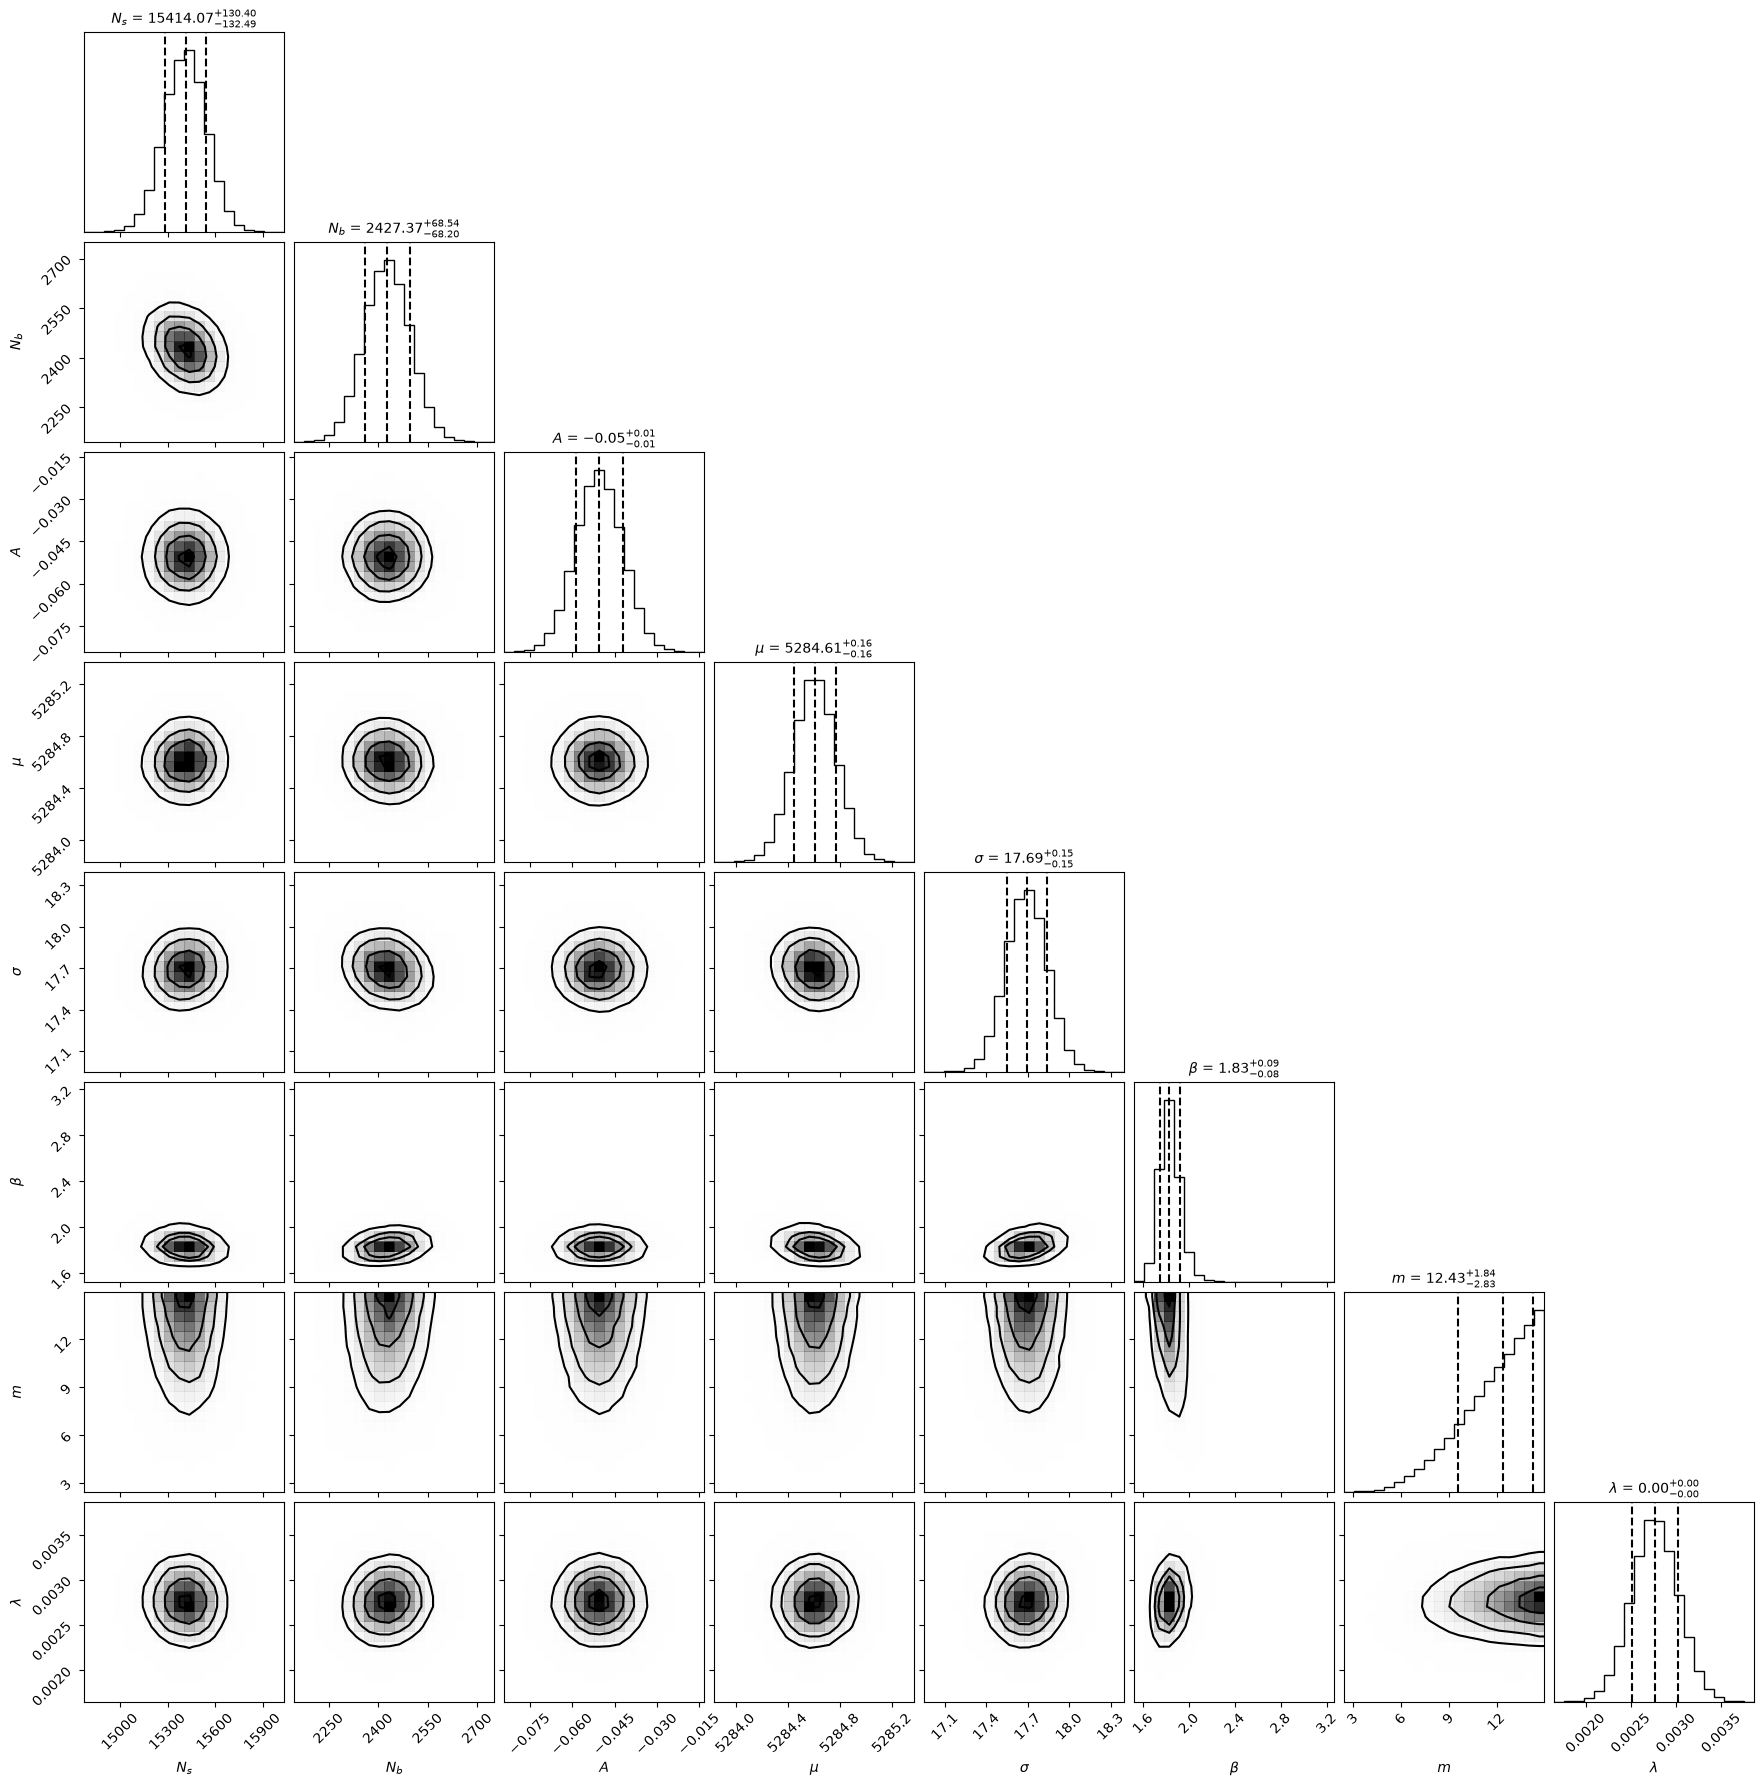

beta fittato = 1.83, m fittato = 12.43 (vs 1.5/3.0 fissati prima)
A_raw (Crystal Ball, beta/m liberi) = -0.0504  68% CI=[-0.0586,-0.0421]
Crystal Ball (beta,m liberi) chi2/ndof = 103.8 / 52 = 2.00
confronto: gaussiana=2.36  CB fissata=4.50  CB libera=2.00
[checkpoint] saved /Users/gmoretti/Work/fededegu_martiborsa/LHCb/Code_general/Bayesian/results/crystal_ball_free_checkpoint.json


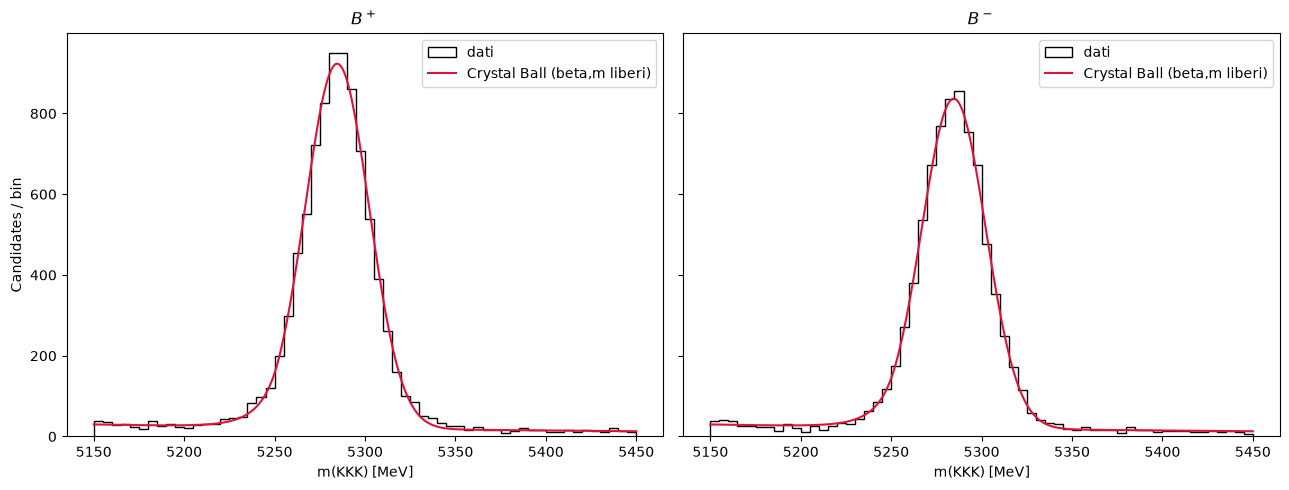

In [25]:
discard_cbf = nsteps_cbf // 6
flat_cbf = sampler_cbf.get_chain(discard=discard_cbf, flat=True)
labels_cbf = [r"$N_s$", r"$N_b$", r"$A$", r"$\mu$", r"$\sigma$", r"$\beta$", r"$m$", r"$\lambda$"]

fig = corner.corner(flat_cbf, labels=labels_cbf, quantiles=[0.16, 0.5, 0.84],
                     show_titles=True, plot_datapoints=False, title_kwargs={"fontsize": 10})
plt.show()

A_cbf = flat_cbf[:, 2]
A_median_cbf = float(np.median(A_cbf))
ci68_cbf = [float(x) for x in np.percentile(A_cbf, [16, 84])]
theta_med_cbf = np.median(flat_cbf, axis=0)
N_s_f, N_b_f, A_f, mu_f, sigma_f, beta_f, m_f, lam_f = theta_med_cbf
print(f"beta fittato = {beta_f:.2f}, m fittato = {m_f:.2f} (vs 1.5/3.0 fissati prima)")
print(f"A_raw (Crystal Ball, beta/m liberi) = {A_median_cbf:.4f}  68% CI=[{ci68_cbf[0]:.4f},{ci68_cbf[1]:.4f}]")

N_s_plus_f, N_s_minus_f, N_b_half_f = N_s_f*(1-A_f)/2, N_s_f*(1+A_f)/2, N_b_f/2

def signal_pdf_cbf(m_, mu_, sigma_, beta_, tail_m_, lo, hi):
    nc = _cb.cdf((hi - mu_) / sigma_, beta_, tail_m_) - _cb.cdf((lo - mu_) / sigma_, beta_, tail_m_)
    return _cb.pdf((m_ - mu_) / sigma_, beta_, tail_m_) / sigma_ / nc

def binned_gof_cbf(m_data, bin_edges, N_s_q, N_b_half_):
    bw = bin_edges[1] - bin_edges[0]
    obs, _ = np.histogram(m_data, bins=bin_edges)
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    exp = (N_s_q * signal_pdf_cbf(centers, mu_f, sigma_f, beta_f, m_f, bm.MASS_LO, bm.MASS_HI)
           + N_b_half_ * background_pdf_exp_w(centers, lam_f, bm.MASS_LO, bm.MASS_HI)) * bw
    return np.sum((obs - exp)**2 / np.maximum(exp, 1e-9))

chi2_cbf = (binned_gof_cbf(m_obs[q_obs > 0], gof_bins, N_s_plus_f, N_b_half_f)
            + binned_gof_cbf(m_obs[q_obs < 0], gof_bins, N_s_minus_f, N_b_half_f))
ndof_cbf = 2 * (len(gof_bins) - 1) - ndim_cbf
print(f"Crystal Ball (beta,m liberi) chi2/ndof = {chi2_cbf:.1f} / {ndof_cbf} = {chi2_cbf/ndof_cbf:.2f}")
print(f"confronto: gaussiana={chi2_tot/ndof:.2f}  CB fissata={chi2_cb/ndof:.2f}  CB libera={chi2_cbf/ndof_cbf:.2f}")

checkpoint_save("crystal_ball_free_checkpoint", {
    "A_raw_median": A_median_cbf, "A_raw_ci68": ci68_cbf, "chi2_over_ndof": float(chi2_cbf/ndof_cbf),
    "beta_fitted": float(beta_f), "m_fitted": float(m_f),
})

m_grid_cbf = np.linspace(bm.MASS_LO, bm.MASS_HI, 300)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, q_sign, N_s_q, label in ((axes[0], 1, N_s_plus_f, r"$B^+$"), (axes[1], -1, N_s_minus_f, r"$B^-$")):
    ax.hist(m_obs[q_obs == q_sign], bins=bins, histtype="step", color="k", label="dati")
    curve = (N_s_q * signal_pdf_cbf(m_grid_cbf, mu_f, sigma_f, beta_f, m_f, bm.MASS_LO, bm.MASS_HI)
             + N_b_half_f * background_pdf_exp_w(m_grid_cbf, lam_f, bm.MASS_LO, bm.MASS_HI)) * (bins[1]-bins[0])
    ax.plot(m_grid_cbf, curve, color="crimson", label="Crystal Ball (beta,m liberi)")
    ax.set_xlabel("m(KKK) [MeV]"); ax.set_title(label); ax.legend()
axes[0].set_ylabel("Candidates / bin")
plt.tight_layout()
plt.show()

## Confronto con i valori pubblicati

Il nostro $A_{raw}$ non è corretto per efficienza di selezione né per asimmetria di produzione del B -- non è direttamente confrontabile con l'$A_{CP}$ misurato da LHCb. Il confronto qui sotto è solo qualitativo (stesso segno, stesso ordine di grandezza), a illustrare perché $A_{raw} \neq A_{CP}$, come già discusso nella proposta.

In [26]:
published_ACP_KKK = -0.037
published_ACP_KKK_err = (0.002**2 + 0.002**2 + 0.003**2)**0.5  # stat (+) syst (+) J/psi K, PRD 108 (2023) 012008

print(f"{'Quantita':<45s}{'Valore':>18s}")
print("-" * 63)
print(f"{'A_raw (nostro, bayesiano, non corretto)':<45s}{A_median:+.4f} [{ci68[0]:+.4f},{ci68[1]:+.4f}]")
print(f"{'A_raw (conteggio grezzo, sanity check)':<45s}{(np.sum(q_obs<0)-np.sum(q_obs>0))/len(q_obs):+.4f}")
print(f"{'A_CP pubblicato (arXiv:2403.19921, KKK)':<45s}{published_ACP_KKK:+.4f} +- {published_ACP_KKK_err:.4f}")
print()
print(f"Stesso segno: {'si' if np.sign(A_median)==np.sign(published_ACP_KKK) else 'no'}.",
      f"Rapporto |nostro/pubblicato| = {abs(A_median/published_ACP_KKK):.2f}",
      "-- ordine di grandezza comparabile, come atteso da una quantita' grezza non corretta.")

Quantita                                                 Valore
---------------------------------------------------------------
A_raw (nostro, bayesiano, non corretto)      -0.0497 [-0.0579,-0.0413]
A_raw (conteggio grezzo, sanity check)       -0.0492
A_CP pubblicato (arXiv:2403.19921, KKK)      -0.0370 +- 0.0028

Stesso segno: si. Rapporto |nostro/pubblicato| = 1.34 -- ordine di grandezza comparabile, come atteso da una quantita' grezza non corretta.


## Dalitz plot e asimmetrie locali

Nel dataset, per convenzione, **H1 è sempre il kaone di carica opposta agli altri due** (verificato: solo le combinazioni di carica (+1,-1,-1) e (-1,+1,+1) esistono per (H1,H2,H3)) -- quindi H2/H3 sono sempre la coppia dello stesso segno e sono intercambiabili: le due masse invarianti $m^2(H1,H2)$ e $m^2(H1,H3)$ vengono ordinate (`m2_lo`, `m2_hi`) per rimuovere questa ambiguita' di etichettatura, come suggerito dal notebook ufficiale ("Ordering Dalitz variables").

In [27]:
charges_arr = data[["H1_Charge", "H2_Charge", "H3_Charge"]].to_numpy()
Bc_arr = data["B_Charge"].to_numpy()
is_bachelor = charges_arr != np.sign(Bc_arr)[:, None]
assert np.all(is_bachelor.sum(axis=1) == 1), "atteso esattamente un bachelor per evento"
bach_idx = np.argmax(is_bachelor, axis=1)
same_idx = np.array([[j for j in range(3) if j != b] for b in bach_idx])

E_cols = data[["H1_E", "H2_E", "H3_E"]].to_numpy()
Px_cols = data[["H1_PX", "H2_PX", "H3_PX"]].to_numpy()
Py_cols = data[["H1_PY", "H2_PY", "H3_PY"]].to_numpy()
Pz_cols = data[["H1_PZ", "H2_PZ", "H3_PZ"]].to_numpy()
rows = np.arange(len(data))

def pair_m2(i_idx, j_idx):
    E = E_cols[rows, i_idx] + E_cols[rows, j_idx]
    Px = Px_cols[rows, i_idx] + Px_cols[rows, j_idx]
    Py = Py_cols[rows, i_idx] + Py_cols[rows, j_idx]
    Pz = Pz_cols[rows, i_idx] + Pz_cols[rows, j_idx]
    return (E**2 - (Px**2 + Py**2 + Pz**2)) / 1e6  # GeV^2

m2_a = pair_m2(bach_idx, same_idx[:, 0])
m2_b = pair_m2(bach_idx, same_idx[:, 1])
m2_lo_dz = np.minimum(m2_a, m2_b)
m2_hi_dz = np.maximum(m2_a, m2_b)

q_dz = data["B_Charge"].to_numpy()
print(f"m2_lo range: [{m2_lo_dz.min():.2f}, {m2_lo_dz.max():.2f}] GeV^2")
print(f"m2_hi range: [{m2_hi_dz.min():.2f}, {m2_hi_dz.max():.2f}] GeV^2")

m2_lo range: [0.98, 14.29] GeV^2
m2_hi range: [2.86, 24.01] GeV^2


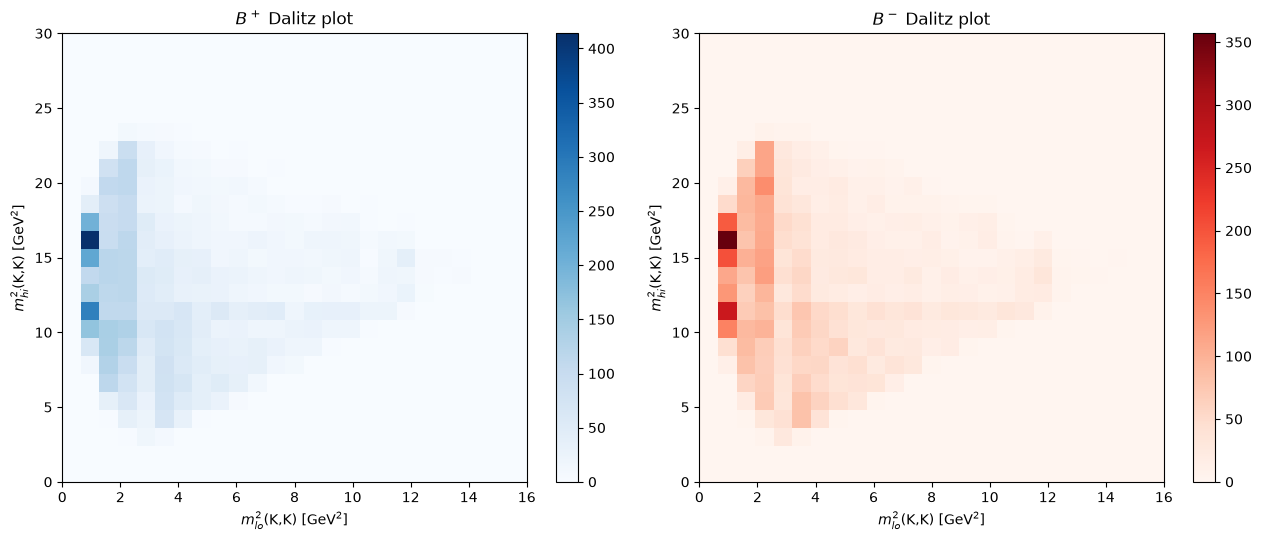

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
dz_range = [[0, 16], [0, 30]]
h_p = axes[0].hist2d(m2_lo_dz[q_dz > 0], m2_hi_dz[q_dz > 0], bins=25, range=dz_range, cmap="Blues")
axes[0].set_title(r"$B^+$ Dalitz plot")
h_m = axes[1].hist2d(m2_lo_dz[q_dz < 0], m2_hi_dz[q_dz < 0], bins=25, range=dz_range, cmap="Reds")
axes[1].set_title(r"$B^-$ Dalitz plot")
for ax, h in zip(axes, (h_p, h_m)):
    ax.set_xlabel(r"$m^2_{lo}$(K,K) [GeV$^2$]")
    ax.set_ylabel(r"$m^2_{hi}$(K,K) [GeV$^2$]")
    plt.colorbar(h[3], ax=ax)
plt.tight_layout()
plt.show()

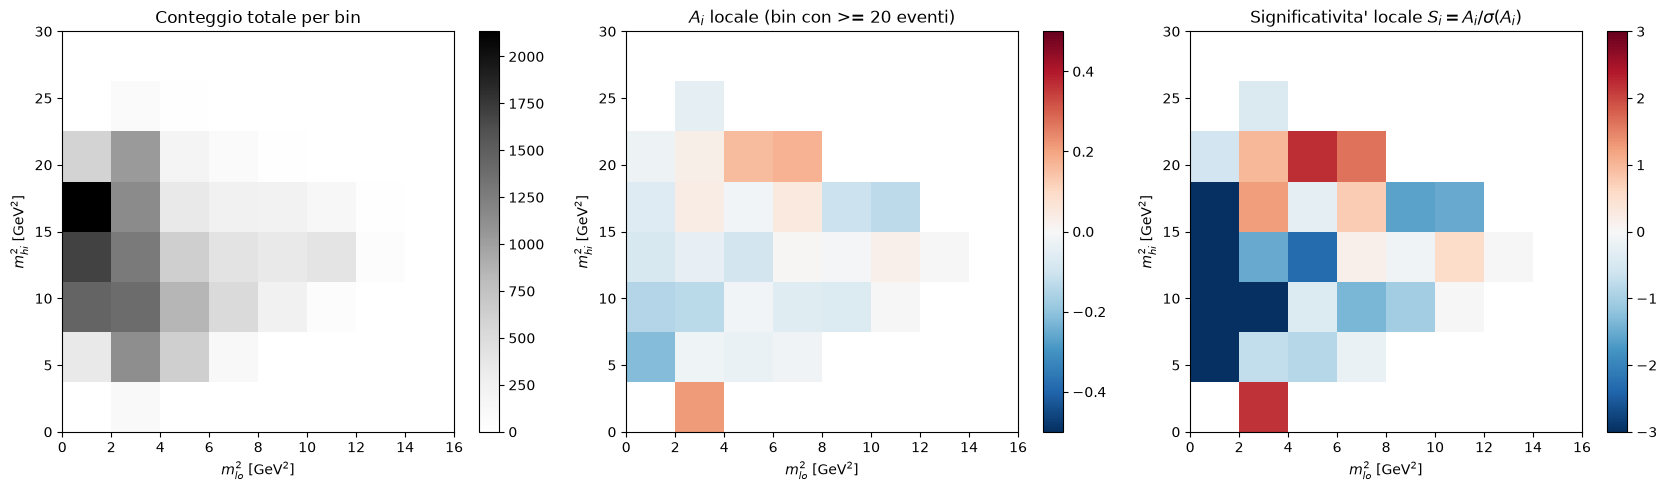

bin con |S_i| > 3 (potenzialmente interessanti): 4 su 29 bin popolati


In [29]:
nbins_dz = 8
edges_lo = np.linspace(dz_range[0][0], dz_range[0][1], nbins_dz + 1)
edges_hi = np.linspace(dz_range[1][0], dz_range[1][1], nbins_dz + 1)

N_plus, _, _ = np.histogram2d(m2_lo_dz[q_dz > 0], m2_hi_dz[q_dz > 0], bins=[edges_lo, edges_hi])
N_minus, _, _ = np.histogram2d(m2_lo_dz[q_dz < 0], m2_hi_dz[q_dz < 0], bins=[edges_lo, edges_hi])

N_tot = N_plus + N_minus
with np.errstate(divide="ignore", invalid="ignore"):
    A_local = np.where(N_tot > 0, (N_minus - N_plus) / N_tot, np.nan)
    sigma_A_local = np.where(N_tot > 0, np.sqrt(np.maximum(1 - A_local**2, 0) / N_tot), np.nan)
    S_local = np.where(sigma_A_local > 0, A_local / sigma_A_local, np.nan)

min_events_per_bin = 20
A_local_masked = np.where(N_tot >= min_events_per_bin, A_local, np.nan)
S_local_masked = np.where(N_tot >= min_events_per_bin, S_local, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
im0 = axes[0].imshow(N_tot.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="Greys")
axes[0].set_title("Conteggio totale per bin"); plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(A_local_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title(f"$A_i$ locale (bin con >= {min_events_per_bin} eventi)"); plt.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(S_local_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-3, vmax=3)
axes[2].set_title("Significativita' locale $S_i = A_i/\\sigma(A_i)$"); plt.colorbar(im2, ax=axes[2])
for ax in axes:
    ax.set_xlabel(r"$m^2_{lo}$ [GeV$^2$]"); ax.set_ylabel(r"$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout()
plt.show()

n_significant = np.sum(np.abs(S_local_masked) > 3)
print(f"bin con |S_i| > 3 (potenzialmente interessanti): {n_significant} su {np.sum(N_tot >= min_events_per_bin)} bin popolati")

# significativita' rispetto all'asimmetria GLOBALE (il test contro zero sopra riflette in parte A_glob stessa)
A_glob_dz = (np.sum(q_dz < 0) - np.sum(q_dz > 0)) / len(q_dz)
pop = N_tot >= min_events_per_bin
S_glob = (A_local[pop] - A_glob_dz) / sigma_A_local[pop]
n_significant_glob = int(np.sum(np.abs(S_glob) > 3))
chi2_hom = float(np.sum(S_glob**2)); ndof_hom = int(pop.sum() - 1)
from scipy.stats import chi2 as _chi2_dz
p_hom = float(_chi2_dz.sf(chi2_hom, ndof_hom))
print(f"rispetto ad A_glob={A_glob_dz:.4f}: {n_significant_glob} bin con |S_i|>3; "
      f"omogeneita' chi2={chi2_hom:.1f}/{ndof_hom}, p={p_hom:.1e}")

### Dalitz locale ristretto alla finestra di segnale (meno contaminato dal fondo)

La mappa sopra usa *tutti* gli eventi nella finestra di fit [5150,5450] MeV, quindi include il fondo combinatorio. Qui restringiamo a $|m - \mu| < 2\sigma$ (~5253-5313 MeV, purezza di segnale stimata >95% dai conteggi sideband/segnale visti all'inizio) per un confronto meno contaminato -- non e' un vero sWeight/background-subtraction, ma un taglio piu' stringente che riduce di molto il contributo del fondo.

eventi in |m-mu|<2*sigma: 15119 (vs 17839 nella finestra di fit completa)


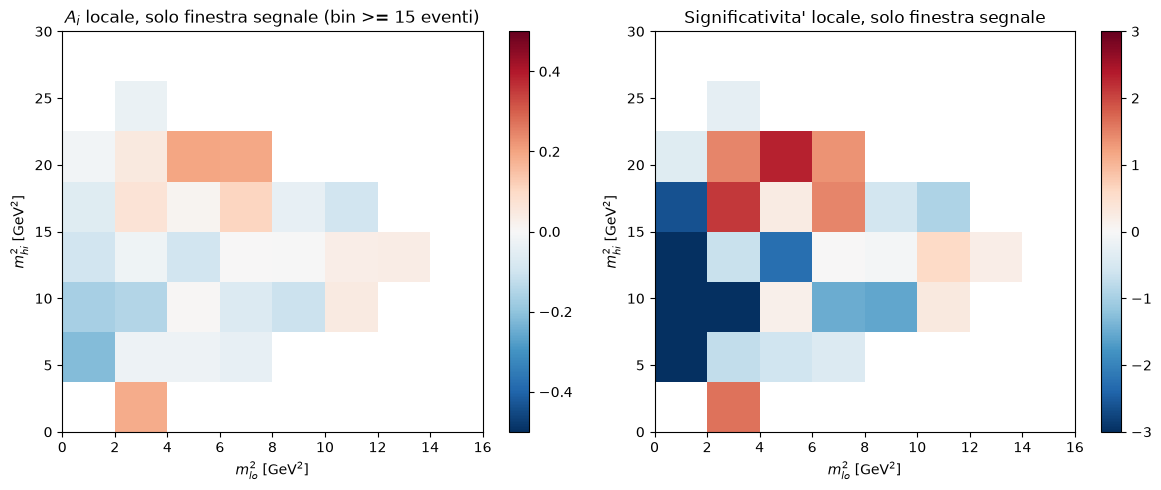

finestra segnale: 29 bin popolati, 4 con |S_i|>3 -- confronta con 29/4 della mappa a finestra piena


In [30]:
sig_window_mask = np.abs(m_obs - mu) < 2 * sigma
m2_lo_sig = m2_lo_dz[sig_window_mask]
m2_hi_sig = m2_hi_dz[sig_window_mask]
q_sig = q_dz[sig_window_mask]
print(f"eventi in |m-mu|<2*sigma: {sig_window_mask.sum()} (vs {len(m_obs)} nella finestra di fit completa)")

N_plus_sig, _, _ = np.histogram2d(m2_lo_sig[q_sig > 0], m2_hi_sig[q_sig > 0], bins=[edges_lo, edges_hi])
N_minus_sig, _, _ = np.histogram2d(m2_lo_sig[q_sig < 0], m2_hi_sig[q_sig < 0], bins=[edges_lo, edges_hi])
N_tot_sig = N_plus_sig + N_minus_sig

with np.errstate(divide="ignore", invalid="ignore"):
    A_local_sig = np.where(N_tot_sig > 0, (N_minus_sig - N_plus_sig) / N_tot_sig, np.nan)
    sigma_A_sig = np.where(N_tot_sig > 0, np.sqrt(np.maximum(1 - A_local_sig**2, 0) / N_tot_sig), np.nan)
    S_local_sig = np.where(sigma_A_sig > 0, A_local_sig / sigma_A_sig, np.nan)

min_events_sig = 20  # stessa soglia della mappa a finestra piena
A_local_sig_masked = np.where(N_tot_sig >= min_events_sig, A_local_sig, np.nan)
S_local_sig_masked = np.where(N_tot_sig >= min_events_sig, S_local_sig, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(A_local_sig_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[0].set_title(f"$A_i$ locale, solo finestra segnale (bin >= {min_events_sig} eventi)")
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(S_local_sig_masked.T, origin="lower", aspect="auto",
                      extent=[*dz_range[0], *dz_range[1]], cmap="RdBu_r", vmin=-3, vmax=3)
axes[1].set_title("Significativita' locale, solo finestra segnale")
plt.colorbar(im1, ax=axes[1])
for ax in axes:
    ax.set_xlabel(r"$m^2_{lo}$ [GeV$^2$]"); ax.set_ylabel(r"$m^2_{hi}$ [GeV$^2$]")
plt.tight_layout()
plt.show()

n_pop_sig = int(np.sum(N_tot_sig >= min_events_sig))
n_sig_sig = int(np.sum(np.abs(S_local_sig_masked) > 3))
print(f"finestra segnale: {n_pop_sig} bin popolati, {n_sig_sig} con |S_i|>3 -- confronta con {int(np.sum(N_tot >= min_events_per_bin))}/{n_significant} della mappa a finestra piena")

A_glob_sig = (np.sum(q_sig < 0) - np.sum(q_sig > 0)) / len(q_sig)
pop_sig = N_tot_sig >= min_events_sig
S_glob_sig = (A_local_sig[pop_sig] - A_glob_sig) / sigma_A_sig[pop_sig]
n_sig_glob_sig = int(np.sum(np.abs(S_glob_sig) > 3))
chi2_hom_sig = float(np.sum(S_glob_sig**2)); ndof_hom_sig = int(pop_sig.sum() - 1)
print(f"finestra segnale, rispetto ad A_glob={A_glob_sig:.4f}: {n_sig_glob_sig} bin con |S_i|>3; "
      f"omogeneita' chi2={chi2_hom_sig:.1f}/{ndof_hom_sig}")

## Salvataggio risultati

Salvati in `results/` così il notebook di confronto finale (blocco 6 della pipeline) non deve rifare girare l'MCMC.

In [31]:
np.savez(os.path.join(RESULTS_DIR, "mcmc_chain.npz"), chain=sampler.get_chain(), flat_samples=flat_samples,
         discard=discard, param_names=bm.PARAM_NAMES)

summary = {
    "sideband_symmetry_checkpoint": {"mu_post": float(mu_post), "sigma_post": float(sigma_post),
                                    "n_sideband": n_tot_sb, "n_plus": n_plus_sb, "n_minus": n_minus_sb,
                                    "A_sideband": float(A_sb), "sigma_A_sideband": float(sigma_A_sb)},
    "n_events_fit_window": int(len(m_obs)),
    "mass_window_MeV": [bm.MASS_LO, bm.MASS_HI],
    "A_raw_median": float(A_median),
    "A_raw_ci68": [float(ci68[0]), float(ci68[1])],
    "A_raw_ci95": [float(ci95[0]), float(ci95[1])],
    "bayes_factor_A0_vs_Afree": float(BF_01),
    "bayes_factor_gaussian_approx": float(BF_01_gauss),
    "bayes_factor_bandwidth_sensitivity": {f"x{m}": float(b) for m, b in zip(bw_multipliers, bf_vs_bw)},
    "mean_acceptance_fraction": float(np.mean(sampler.acceptance_fraction)),
    "nwalkers": nwalkers, "nsteps": nsteps, "discard": discard,
    "magnet_down": {"n": result_down["n"], "A_median": result_down["A_median"], "A_ci68": result_down["A_ci68"]},
    "magnet_up": {"n": result_up["n"], "A_median": result_up["A_median"], "A_ci68": result_up["A_ci68"]},
    "toy_mc_coverage": {
        "n_toys": N_TOYS, "nsteps_toy": NSTEPS_TOY,
        "empirical_coverage_68": cov68_frac, "empirical_coverage_95": cov95_frac,
        "nominal_68": 0.68, "nominal_95": 0.95,
    },
    "systematic_variations": syst_results,
    "free_background_asymmetry": free_bkg_summary,
    "dispersed_start_runs": dispersed_summary,
    "charm_vetoes": charm_veto_summary,
    "toy_mc_estimates": {"bias": toy_bias, "bias_err": toy_bias_err, "sd": toy_sd, "posterior_sd_data": float(np.std(A_samples))},
    "goodness_of_fit": {"chi2_total": float(chi2_tot), "ndof": int(ndof), "chi2_over_ndof": float(chi2_tot/ndof)},
    "goodness_of_fit_crystal_ball": {"A_raw_median": A_median_cb, "A_raw_ci68": ci68_cb,
                                      "chi2_over_ndof": float(chi2_cb/ndof), "beta_fixed": CB_BETA, "m_fixed": CB_M},
    "goodness_of_fit_crystal_ball_free": {"A_raw_median": A_median_cbf, "A_raw_ci68": ci68_cbf,
                                           "chi2_over_ndof": float(chi2_cbf/ndof_cbf),
                                           "beta_fitted": float(beta_f), "m_fitted": float(m_f),
                                           "nwalkers": nwalkers_cbf, "nsteps": nsteps_cbf},
    "published_comparison": {"A_CP_published_KKK": published_ACP_KKK, "A_CP_published_err": published_ACP_KKK_err},
    "dalitz_local_asymmetry": {"n_bins_populated": int(np.sum(N_tot >= min_events_per_bin)),
                                "n_bins_significant_3sigma": int(n_significant),
                                "A_glob": float(A_glob_dz), "n_bins_significant_3sigma_vs_global": n_significant_glob,
                                "chi2_homogeneity": chi2_hom, "ndof_homogeneity": ndof_hom, "p_homogeneity": p_hom},
    "dalitz_local_asymmetry_signal_window": {"n_events": int(sig_window_mask.sum()),
                                              "n_bins_populated": n_pop_sig, "n_bins_significant_3sigma": n_sig_sig,
                                              "n_bins_significant_3sigma_vs_global": n_sig_glob_sig,
                                              "chi2_homogeneity": chi2_hom_sig, "ndof_homogeneity": ndof_hom_sig},
}
with open(os.path.join(RESULTS_DIR, "posterior_summary.json"), "w") as f:
    _json.dump(summary, f, indent=2)

print(_json.dumps(summary, indent=2))

{
  "sideband_symmetry_checkpoint": {
    "mu_post": 5284.409866809464,
    "sigma_post": 17.948108073420144,
    "n_sideband": 1217,
    "n_plus": 637,
    "n_minus": 580,
    "A_sideband": -0.04683648315529992,
    "sigma_A_sideband": 0.028633724447151496
  },
  "n_events_fit_window": 17839,
  "mass_window_MeV": [
    5150.0,
    5450.0
  ],
  "A_raw_median": -0.04972502482826961,
  "A_raw_ci68": [
    -0.05787008000900426,
    -0.04134353011281907
  ],
  "A_raw_ci95": [
    -0.06591755855055995,
    -0.03309108295283332
  ],
  "bayes_factor_A0_vs_Afree": 3.213500282495621e-59,
  "bayes_factor_bandwidth_sensitivity": {
    "x0.5": 2.499538538341949e-228,
    "x1.0": 3.213500282495621e-59,
    "x1.5": 5.048202943988181e-28,
    "x2.0": 3.6181408774644504e-17,
    "x3.0": 1.6807230040420198e-09
  },
  "mean_acceptance_fraction": 0.5170868055555555,
  "nwalkers": 32,
  "nsteps": 9000,
  "discard": 1500,
  "magnet_down": {
    "n": 10500,
    "A_median": -0.05480742097304554,
    "A_ci68

## Limiti noti e prossimi passi

- **Confronto con MLE/profile likelihood**: non ancora possibile, dipende dal fit frequentista di Marco (branch `freq`) sullo stesso modello di massa. Tutto il resto sotto e' stato fatto senza bisogno del suo branch -- lo scope bayesiano della proposta e' ora sostanzialmente esaurito.
- **Fondo diviso equamente fra le cariche** ($N_b/2$, $N_b/2$): assunzione di nessuna asimmetria di fondo, verificata sia indirettamente (cross-check Magnet Up/Down, nessun segno evidente di problema) sia direttamente (conteggio nelle sidebands, $A_{sideband}=-0.047\pm0.029$, compatibile con zero a 1.6$\sigma$) -- nessuna delle due ha pero' potere statistico sufficiente per escludere del tutto una vera asimmetria di fondo delle stesse dimensioni di quella di segnale.
- **Bayes factor via Savage-Dickey**: sensibilita' al bandwidth esplicitamente caratterizzata -- il valore esatto resta inaffidabile (varia di molti ordini di grandezza), solo la conclusione qualitativa (evidenza estrema contro A=0) e' robusta.
- **Toy-MC coverage check**: risolto. Prima passata (60 repliche, poi 100, catena 3000-3500 step) mostrava un'ipotesi di undercoverage a ~1.3$\sigma$; con 500 repliche (3500 step) la copertura empirica 68% e' 0.664 contro il nominale 0.68 -- solo 0.77$\sigma$, dentro il rumore statistico atteso. Copertura 95% = 0.962 (nominale 0.95).
- **Studio sistematico**: le 4 varianti ora usano la stessa lunghezza di catena della fit nominale (9000 step, 32 walker) -- inizialmente accorciate a 2500 step/24 walker per velocita', poi allungate per conferma definitiva.
- **Goodness-of-fit**: il modello gaussiana pura non descrive bene i dati (chi2/ndof=2.36). La Crystal Ball con parametri di coda fissati a valori di letteratura peggiora il fit (chi2/ndof=4.50) -- quei valori non descrivono la coda di questo dataset. Lasciando $\beta,m$ liberi (fit a 8 parametri) il chi2/ndof migliora a 2.00 ($\beta=1.83$, $m=12.4$, lontani dalla letteratura) -- meglio, ma non $\approx1$: un modello a due componenti come nel paper di riferimento sarebbe il passo successivo per un fit pubblicabile.
- **Dalitz plot**: binning grossolano (8x8); la versione ristretta alla finestra di segnale (|m-mu|<2sigma) riduce ma non elimina la contaminazione da fondo -- un vero sWeight/sideband-subtraction locale sarebbe il passo successivo per un risultato pubblicabile.